In [1]:
%load_ext autoreload
%autoreload 2

In [61]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import time
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import MSTL
from statsmodels.stats.diagnostic import acorr_ljungbox


import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)


from common import make_features, evaluate, fit_eval, summarize, save_results, save_result, load_results

# SARIMAX: Daily Electricity Consumption

**Contents**

1. Data: feature engineering, train / validation / test split
2. Time series analysis of the target
   - Stationarity, MSTL
3. Features analysis
   - Dummies, correlation analysis, excluded features
4. Model 1: seasonal difference ($\Delta_7$), month dummies
   - Stationarity of y and the X, standardization, slicing, fitting (baselines, order selection, residual analysis), conclusion
5. Model 2: no differencing, day-of-week dummies, yearly Fourier terms
   - Stationarity of the regression residuals, order selection, number of Fourier pairs K, residual analysis, conclusion
6. Model 1 vs. Model 2
7. Final model evaluation
   - Validation: forecast horizons h = 1 to 7
   - Test: forecasts on 2024
8. Conclusion

**Data split:** fit 2019–2022, validation 2023, test 2024 (the final model is refitted on 2019–2023 for the test).


# Data

### Feature Engineering 
Add some features that might be helpful:
- Interaction term between holiday and weekends.
- Computed solar generation calculated by `solar_capacity_mw` * `shortwave_radiation_sum`

In [3]:
data_daily = pd.read_csv(
    "../../data/final/data_daily.csv",
    parse_dates = ['date_from', 'date_from_utc'])

data_daily.index = pd.to_datetime(data_daily["date_from"]).values
# interaction term and solar generation proxy, see common.py
data_daily = make_features(data_daily)

### Train (and Val), Test split

Use 2024-01-01 as the cutting point:
- 5/6 of the data goes to train/val set
- 1/6 of the data goes to the test set

In [4]:
CUTOFF = '2024-01-01'
data_daily_train = data_daily[data_daily['date_from'] < CUTOFF]
data_daily_test = data_daily[data_daily['date_from'] >= CUTOFF]

In [5]:
data_daily_train.columns

Index(['Unnamed: 0', 'date_from', 'date_to', 'date_from_utc',
       'actual_consumption', 'actual_consumption_incl_pumped',
       'hydro_pumped_storage', 'residual_load', 'month', 'day_of_week_raw',
       'day_of_week', 'is_holiday', 'is_weekday', 'weighted_regional_holiday',
       'weighted_school_holiday', 'is_bridge_day', 'is_christmas_new_year',
       'is_dst', 'is_dst_transition_day', 'gas_price_eu_usd',
       'industrial_confidence', 'day_ahead_price_mean', 'day_ahead_price_min',
       'day_ahead_price_max', 'sin_y1', 'cos_y1', 'sin_y2', 'cos_y2', 'sin_y3',
       'cos_y3', 'sin_y4', 'cos_y4', 'sin_y5', 'cos_y5', 'sin_y6', 'cos_y6',
       'sin_y7', 'cos_y7', 'sin_y8', 'cos_y8', 'sin_y9', 'cos_y9', 'sin_y10',
       'cos_y10', 'generation_wind_onshore', 'generation_wind_offshore',
       'generation_solar', 'generation_lignite', 'generation_hard_coal',
       'generation_natural_gas', 'generation_nuclear', 'solar_capacity_mw',
       'oxcgrt_stringency', 'oxcgrt_c1_school'

# Time Series Analysis of the Target (y, `actual consumption`)

## Stationarity 

In [6]:
y = data_daily_train.set_index("date_from")["actual_consumption"]

#### ADF
To check whether the time series has unit root.

In [7]:
adfuller(y, result_object = True)


ADFullerResult
ADF Statistic: -4.14439
P-value: 0.00082
Used Lag: 23
Nobs: 1802
Critical Values: {'1%': np.float64(-3.4339840952648695), '5%': np.float64(-2.8631452508003057), '10%': np.float64(-2.567624583142913)}

P-value = 0.00082 < 0.05 $\to$ Electricity has no unit root.

#### KPSS 
To check whether the series is stationary (rejected: non-stationary)

In [8]:
kpss(y, result_object = True)

/var/folders/5g/49r4l15d2n94wslpp3gvq4zc0000gn/T/ipykernel_40692/911431712.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss(y, result_object = True)


KPSSResult
KPSS Statistic: 1.20204
P-value: 0.01000
Lags: 20
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}

KPSS P-value = 0.01 < 0.05 $\to$ Electricity is non-stationary. 

ADF and KPSS results contradict. Need to be processed further. Analyze the time series by plot and MSTL decomposition.

### MSTL
We check whether there is any seasonality in the electricity consumption by MSLT decomposition.

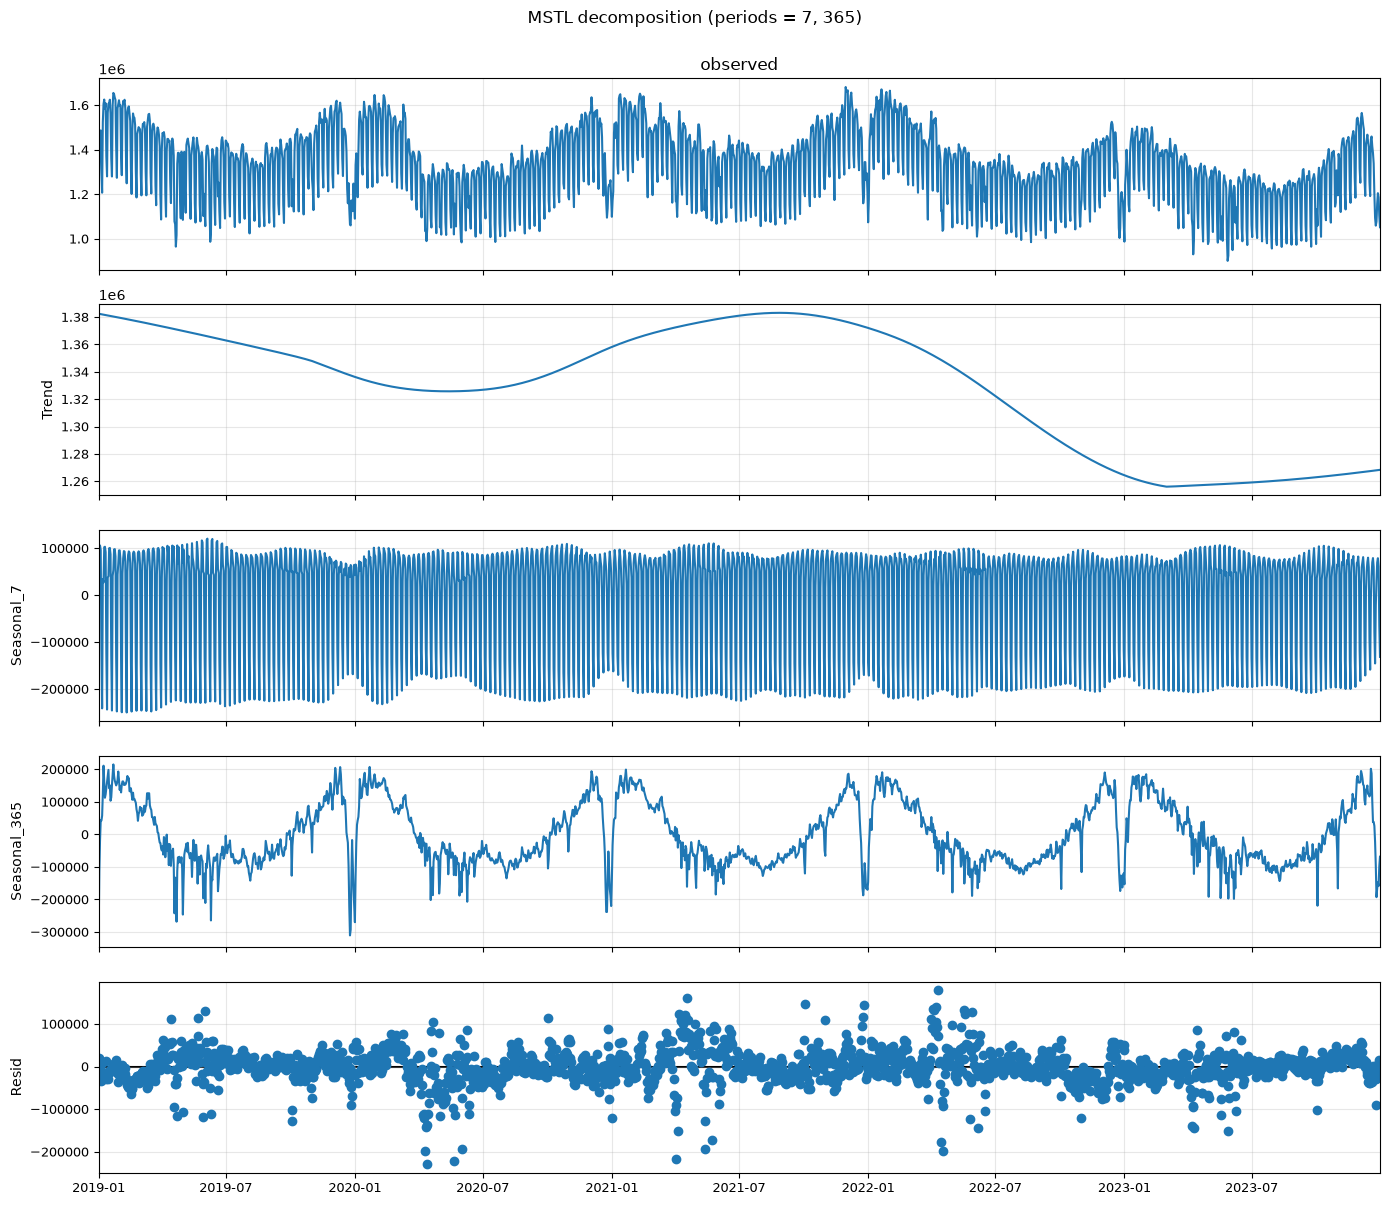

In [9]:
res = MSTL(y, periods=(7, 365)).fit()

fig = res.plot()
fig.set_size_inches(14, 12)
for ax in fig.axes:
    ax.tick_params(labelsize=9)
    ax.grid(alpha = 0.3)
fig.suptitle("MSTL decomposition (periods = 7, 365)", y = 1.0)
plt.tight_layout()
plt.show()


The original time series has a strong seasonality.

- ADF rejects the null of a unit root, so the series has no (non-seasonal) unit root. It does not check for seasonality.
- With strong seasonality the mean is not constant (the rolling mean moves with the season). KPSS accordingly rejects stationarity.

$\to$ The seasonality needs to be handled.

We consider two candidate models:

- **Model 1**: SARIMAX with seasonal differencing (s = 7) for the weekly seasonality, and 11 month dummy variables for the yearly seasonality. (Monthly dummies are experimented with ablation)
- **Model 2**: SARIMAX without differencing (d = D = 0, initially). The weekly seasonality is modelled by 6 day-of-week dummy variables, and the yearly seasonality by **Fourier** terms with period = 365 (and number of terms K to be chosen).

We apply the **Box-Jenkins** method to each model:
1. Make the series stationary where needed, and choose the orders (p, q, P, Q) from the ACF and PACF.
2. Pick the right exogenous variables, fit the model, and get the residuals.
3. Check the residuals: Ljung–Box test and ACF/PACF for remaining autocorrelation, residual plot for constant mean and variance, Q-Q plot for normality.
4. If the check fails, go back to step 1 and adjust the orders.

The two models are compared on the out-of-sample error (rolling-origin), because their **AIC values are not comparable** (different differencing).


# Features Analysis


In [10]:
# fourier term column names 
fourier_terms = [
    f"{fourier}_y{i}"
    for fourier in ["sin", "cos"] 
    for i in range(1, 11)
]

# * Analyze all features that might be used for all models
X_global = data_daily_train[[
    # calendar
    "is_holiday",
    "is_weekday",
    "is_holiday_weekday",                      # * made in make_features, not in the final data 
    "weighted_regional_holiday",
    "weighted_school_holiday",
    "is_bridge_day",
    "is_christmas_new_year",
    "is_dst", "is_dst_transition_day",
    # economic and price
    'industrial_confidence',
    'gas_price_eu_usd',
    'ipi_ei_level',
    'day_ahead_price_mean',
    # weather
    'hdd',
    'daylight_duration',
    'shortwave_radiation_sum',
    'wind_speed_10m_mean', 'precipitation_sum',
    # solar and policy
    'solar_capacity_mw',
    'solar_generation_proxy',                  # * made in make_features, not in the final data 
    'oxcgrt_stringency',
    # fourier terms 
    ] + fourier_terms
].astype(float)


In [11]:
X_global.columns

Index(['is_holiday', 'is_weekday', 'is_holiday_weekday',
       'weighted_regional_holiday', 'weighted_school_holiday', 'is_bridge_day',
       'is_christmas_new_year', 'is_dst', 'is_dst_transition_day',
       'industrial_confidence', 'gas_price_eu_usd', 'ipi_ei_level',
       'day_ahead_price_mean', 'hdd', 'daylight_duration',
       'shortwave_radiation_sum', 'wind_speed_10m_mean', 'precipitation_sum',
       'solar_capacity_mw', 'solar_generation_proxy', 'oxcgrt_stringency',
       'sin_y1', 'sin_y2', 'sin_y3', 'sin_y4', 'sin_y5', 'sin_y6', 'sin_y7',
       'sin_y8', 'sin_y9', 'sin_y10', 'cos_y1', 'cos_y2', 'cos_y3', 'cos_y4',
       'cos_y5', 'cos_y6', 'cos_y7', 'cos_y8', 'cos_y9', 'cos_y10'],
      dtype='str')

## One-hot Encoding for `month` & `day_of_week_raw` dummies

In [12]:
onehotencoder = OneHotEncoder(
    sparse_output = False,
    drop = "first"
).set_output(transform = "pandas")

month_dummies = pd.get_dummies(data_daily_train["month"], prefix = "month", drop_first = True)
dow_dummies = pd.get_dummies(data_daily_train["day_of_week_raw"], prefix = "dow", drop_first = True)
X_global = pd.concat([X_global, month_dummies, dow_dummies], axis = 1).astype(float)

In [13]:
X_global.head(2)

,is_holiday,is_weekday,is_holiday_weekday,weighted_regional_holiday,weighted_school_holiday,is_bridge_day,is_christmas_new_year,is_dst,is_dst_transition_day,industrial_confidence,...,month_9,month_10,month_11,month_12,dow_1,dow_2,dow_3,dow_4,dow_5,dow_6
2019-01-01,1.0,1.0,1.0,0.0,0.448877,0.0,1.0,0.0,0.0,3.8,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2019-01-02,0.0,1.0,0.0,0.0,0.448877,0.0,0.0,0.0,0.0,3.8,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


## Correlation Analysis
### With Fourier Terms & Time Dummies
#### Linear Correlation

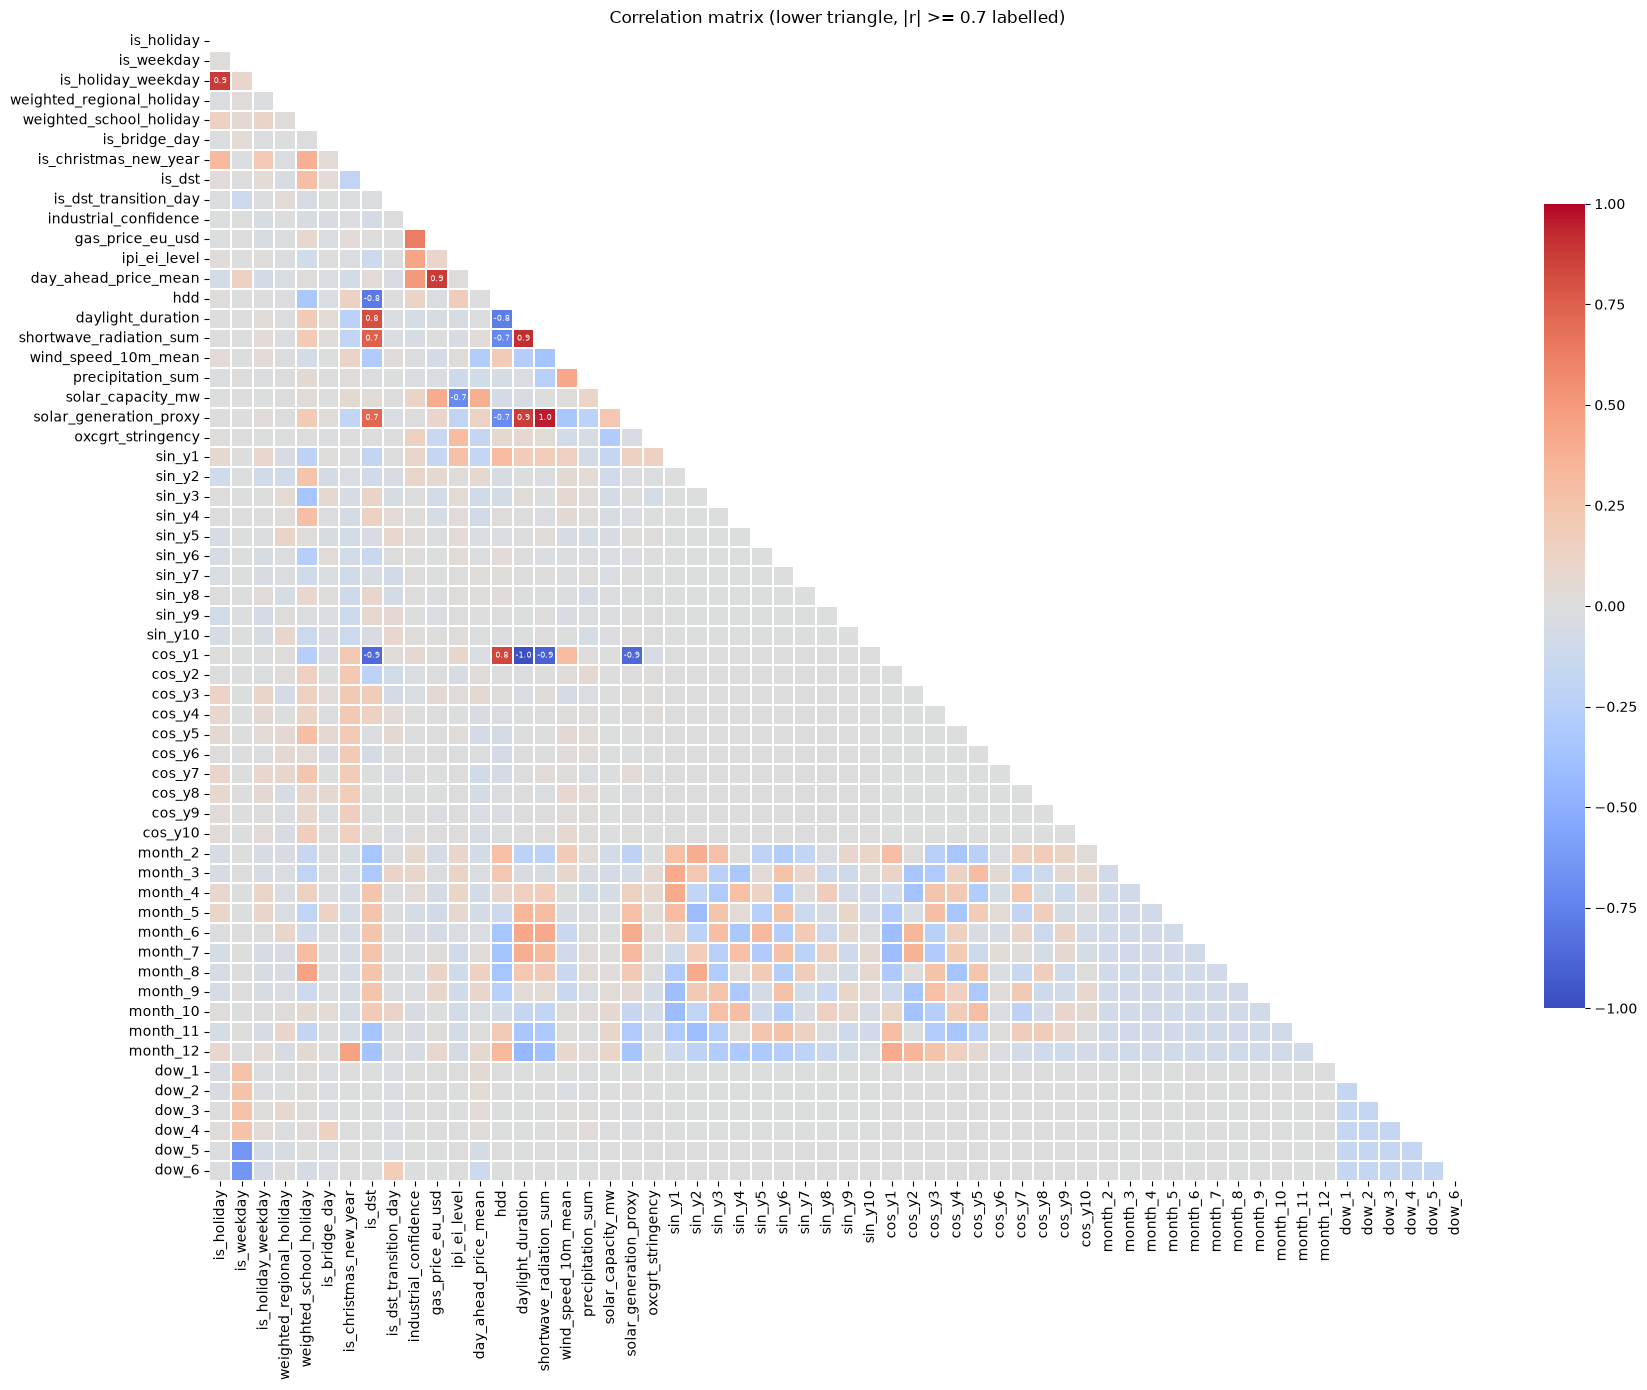

,var_a,var_b,r,abs_r
1812,cos_y1,daylight_duration,-0.981482,0.981482
1117,solar_generation_proxy,shortwave_radiation_sum,0.958216,0.958216
884,shortwave_radiation_sum,daylight_duration,0.917576,0.917576
1813,cos_y1,shortwave_radiation_sum,-0.900020,0.900020
116,is_holiday_weekday,is_holiday,0.879452,0.879452
706,day_ahead_price_mean,gas_price_eu_usd,0.879206,0.879206
1116,solar_generation_proxy,daylight_duration,0.872117,0.872117
1805,cos_y1,is_dst,-0.862985,0.862985
1817,cos_y1,solar_generation_proxy,-0.862168,0.862168
1811,cos_y1,hdd,0.843639,0.843639


In [14]:
corr = X_global.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))         
labels = corr.map(lambda v: f"{v:.1f}" if abs(v) >= 0.7 else "")

plt.figure(figsize=(18, 14))
sns.heatmap(corr, mask=mask, annot=labels, fmt="", annot_kws={"size": 6},
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Correlation matrix (lower triangle, |r| >= 0.7 labelled)")
plt.tight_layout()
plt.show()


# print highly correlated feature pairs
pairs = (corr.where(~mask).stack().rename("r").reset_index()
         .rename(columns={"level_0": "var_a", "level_1": "var_b"}))
pairs["abs_r"] = pairs["r"].abs()
pairs = pairs.sort_values("abs_r", ascending=False)
pairs[pairs["abs_r"] >= 0.7]



#### VIF Analysis

In [15]:
X_vif_global = (
    add_constant(
        X_global
        .astype(float)
        .dropna()
        .drop(columns = ["is_weekday"])     # because this will be colinear with all day_of_week dummies
    )
)

vif_data = pd.DataFrame({
    "feature": X_vif_global.columns[1:],
    "VIF": [variance_inflation_factor(X_vif_global.values, i)
            for i in range(1, X_vif_global.shape[1])]
})
print(vif_data[vif_data["VIF"] >= 3].sort_values("VIF", ascending = False))


                    feature           VIF
13        daylight_duration  3.242251e+06
30                   cos_y1  3.123727e+06
20                   sin_y1  1.143822e+05
32                   cos_y3  3.072237e+03
22                   sin_y3  1.244101e+03
31                   cos_y2  2.894239e+02
14  shortwave_radiation_sum  4.948205e+01
46                  month_8  4.468178e+01
45                  month_7  4.414544e+01
47                  month_9  4.214369e+01
44                  month_6  4.130020e+01
18   solar_generation_proxy  3.986186e+01
43                  month_5  3.901075e+01
48                 month_10  3.858845e+01
42                  month_4  3.404015e+01
49                 month_11  3.126295e+01
6                    is_dst  2.738862e+01
50                 month_12  2.679510e+01
41                  month_3  2.602024e+01
21                   sin_y2  2.451596e+01
40                  month_2  1.515525e+01
24                   sin_y5  1.492062e+01
34                   cos_y5  9.884

### Without Fourier Terms & Time Dummies 

In [16]:
X_global_no_time_features = X_global.drop(
    columns = fourier_terms + list(month_dummies.columns) + list(dow_dummies.columns)
)

#### Linear Correlation

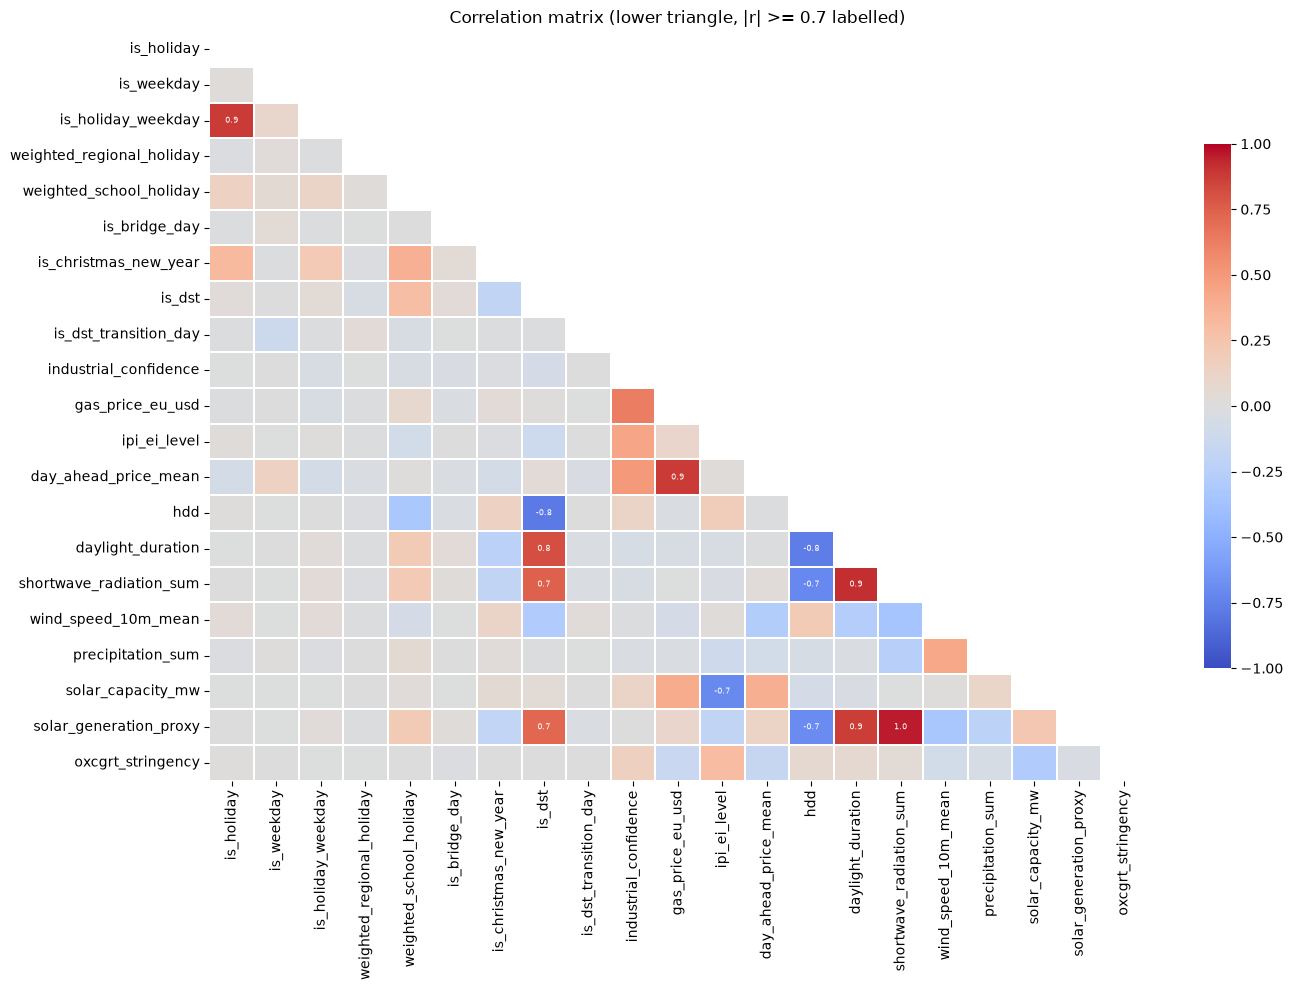

,var_a,var_b,r,abs_r
414,solar_generation_proxy,shortwave_radiation_sum,0.958216,0.958216
329,shortwave_radiation_sum,daylight_duration,0.917576,0.917576
42,is_holiday_weekday,is_holiday,0.879452,0.879452
262,day_ahead_price_mean,gas_price_eu_usd,0.879206,0.879206
413,solar_generation_proxy,daylight_duration,0.872117,0.872117
301,daylight_duration,is_dst,0.813461,0.813461
280,hdd,is_dst,-0.785351,0.785351
307,daylight_duration,hdd,-0.771307,0.771307
322,shortwave_radiation_sum,is_dst,0.746058,0.746058
406,solar_generation_proxy,is_dst,0.721545,0.721545


In [17]:
corr = X_global_no_time_features.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))         
labels = corr.map(lambda v: f"{v:.1f}" if abs(v) >= 0.7 else "")

plt.figure(figsize=(14, 10))
sns.heatmap(corr, mask=mask, annot=labels, fmt="", annot_kws={"size": 6},
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.title("Correlation matrix (lower triangle, |r| >= 0.7 labelled)")
plt.tight_layout()
plt.show()


# print highly correlated feature pairs
pairs = (corr.where(~mask).stack().rename("r").reset_index()
         .rename(columns={"level_0": "var_a", "level_1": "var_b"}))
pairs["abs_r"] = pairs["r"].abs()
pairs = pairs.sort_values("abs_r", ascending=False)
pairs[pairs["abs_r"] >= 0.7]



#### VIF Analysis

In [18]:
X_vif_global = (
    add_constant(
        X_global_no_time_features
        .astype(float)
        .dropna()
        .drop(columns = ["is_weekday"])     # because this will be colinear with all day_of_week dummies
    )
)

vif_data = pd.DataFrame({
    "feature": X_vif_global.columns[1:],
    "VIF": [variance_inflation_factor(X_vif_global.values, i)
            for i in range(1, X_vif_global.shape[1])]
})
print(vif_data[vif_data["VIF"] >= 3].sort_values("VIF", ascending = False))


                    feature        VIF
14  shortwave_radiation_sum  46.399851
18   solar_generation_proxy  38.188196
13        daylight_duration  12.129754
9          gas_price_eu_usd   7.941059
11     day_ahead_price_mean   6.588036
17        solar_capacity_mw   6.246112
10             ipi_ei_level   5.024633
0                is_holiday   4.859618
1        is_holiday_weekday   4.588984
6                    is_dst   3.928840
12                      hdd   3.561670


### Excluded features

The features are chosen before any model is fitted, from the correlation matrix and the VIF above, and in agreement with the tree-based model, so that all models use the same information. Only its representation differs where a model requires it (month dummies in Model 1, day-of-week dummies and yearly Fourier terms in Model 2). There is no ablation afterwards: the set of X is fixed before the validation results are seen.

The table lists the features of the final data that are not used as X.

| Feature | Excluded from | Evidence | Reason |
|---|---|---|---|
| `shortwave_radiation_sum` | all models | VIF 46.4; r = 0.96 with `solar_generation_proxy`, 0.92 with `daylight_duration` | Nearly the same information as the proxy. The proxy (capacity × radiation) is kept, because it also follows the growth of the installed solar capacity, i.e. it measures the solar generation that lowers the measured load. |
| `solar_capacity_mw` | all models | VIF 6.2; r = −0.71 with `ipi_ei_level` | Already contained in the proxy. On its own it is a slowly rising trend, and its correlation with `ipi_ei_level` comes from the two trends, not from a relation between them. |
| `daylight_duration` | all models | VIF 12.1; r = 0.92 with radiation, 0.87 with the proxy, 0.81 with `is_dst`, −0.77 with `hdd` | A deterministic function of the day of the year, so its information is in the yearly Fourier terms (and the month dummies). The tree-based model leaves it out as well. |
| `gas_price_eu_usd` | all models | VIF 7.9; r = 0.88 with `day_ahead_price_mean` | Its VIF is below the usual threshold of 10, but it carries little information beyond the electricity price. Left out to keep the same X as the tree-based model. |
| `is_weekday` | all models | exact collinearity | Replaced by the interaction `is_holiday_weekday` (`is_holiday` × `is_weekday`). In Model 2 it is an exact linear combination of the day-of-week dummies and the constant (rank-deficient design matrix); in Model 1 it is zero after the seasonal difference $\Delta_7$. Its main effect stays in the model through the day-of-week dummies (Model 2) or the seasonal difference (Model 1). |
| `is_dst` | Model 2 only | VIF 3.9 without the Fourier terms, about 22.3 with them | Collinear with `cos_y1`: daylight saving time covers the same half of the year as the first yearly Fourier pair. Model 1 keeps it, because it has no Fourier terms. |
| `generation_*` | all models | – | Leakage: the generation of a day is only known after the day. |

Kept despite a high correlation:

- `is_holiday` and `is_holiday_weekday` (r = 0.88, VIF 4.9 and 4.6): an interaction is correlated with its main effect by construction; both are needed to separate the holiday effect on weekdays from that on weekends.
- `hdd` (r = −0.79 with `is_dst`, VIF 3.6): the VIF is low, and heating demand varies from year to year with the temperature, which a calendar feature does not capture.


In [19]:
drop_cols_global = [
    "is_weekday",
    "daylight_duration",
    "shortwave_radiation_sum", 
    "solar_capacity_mw",
    "gas_price_eu_usd"
]

# * X for speficiation 1
X_m1 = X_global.drop(
    columns = drop_cols_global 
             + fourier_terms                     # year effect explained by "month_{i}"dummies
             + list(dow_dummies.columns)         # week effect absorb by seasonal difference
)

# * X for running the residual test (Preliminary for model 2)
X_prelim = X_global.drop(
    columns = drop_cols_global 
                + ["is_dst"]                     # correlated wit Fourier. Drop first
                + list(month_dummies.columns)
)

# * X for speficiation 2
X_m2 = X_prelim.copy()

# Model 1
SARIMAX with seasonal differencing (s = 7) for the weekly seasonality, and 11-month dummy variables for the yearly seasonality.

## Target y stationarity check

In model 1's setting, we make y stationary by differencing with `s = 7`, to check whether it passes both ADF and KPSS tests.

In [20]:
def test_adf(name, series, width, print_stationary = False):
    adf_res = adfuller(series, result_object=True)
    if adf_res.pvalue > 0.05:
        print(f"{name:<{width}} not stationary (ADF) | p-value = {adf_res.pvalue:8.4f}")
        return False 
    else:
        if print_stationary:
            print(f"{name:<{width}} rejected by ADF      | p-value = {adf_res.pvalue:8.4f}")
        return True

def test_kpss(name, series, width, print_stationary = False):
    res = kpss(series, regression = "c", nlags = "auto", result_object = True)
    if res.pvalue <= 0.05:
        print(f"{name:<{width}} rejected by KPSS     | p-value = {res.pvalue:8.4f}")
        return False
    if print_stationary:
        print(f"{name:<{width}} stationary (KPSS)    | p-value = {res.pvalue:8.4f}")
    return True

In [21]:
y_s7   = y.diff(7).dropna()
test_adf("y delta 7", y_s7, 12, print_stationary = True);

y delta 7    rejected by ADF      | p-value =   0.0000


In [22]:
test_kpss("y delta 7", y_s7, 12, print_stationary = True);


y delta 7    stationary (KPSS)    | p-value =   0.1000


/var/folders/5g/49r4l15d2n94wslpp3gvq4zc0000gn/T/ipykernel_40692/833649152.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  res = kpss(series, regression = "c", nlags = "auto", result_object = True)


**Result**

After differencing by lag = 7 to reduce weekly seasonality, we can see that KPSS result is not rejected. The differenced series can be viewed as stationary.

## ACF & PACF Plot of $y\ \Delta_7$

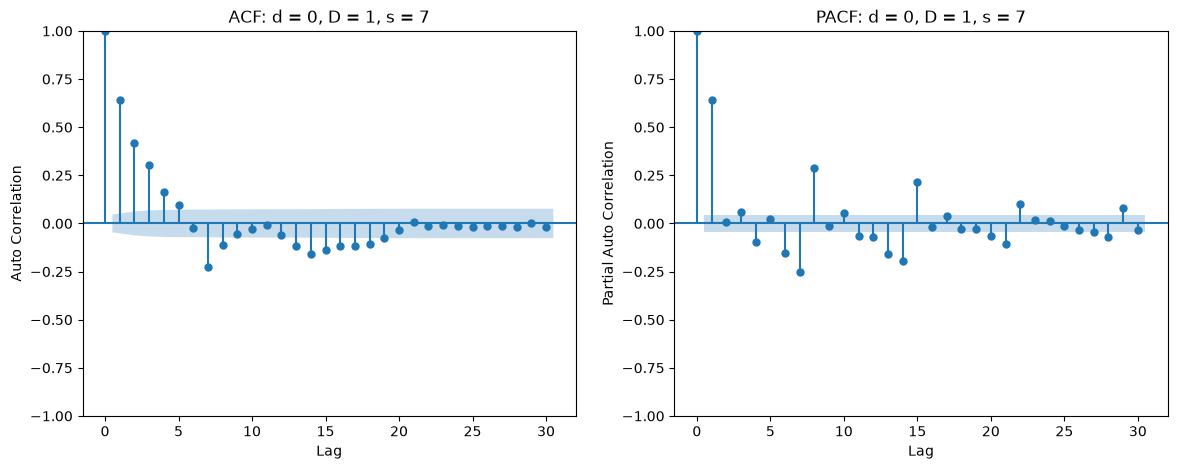

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(y_s7, lags = 30, ax = ax1) 
ax1.set_xlabel("Lag")
ax1.set_ylabel("Auto Correlation")
ax1.set_title("ACF: d = 0, D = 1, s = 7")

plot_pacf(y_s7, lags = 30, ax = ax2) 
ax2.set_xlabel("Lag")
ax2.set_ylabel("Partial Auto Correlation")
ax2.set_title("PACF: d = 0, D = 1, s = 7")
plt.show()

**Conclusions**

The resulting ACF, PACF graphs indicate that:
- PACF cuts off after lag 1: once the value at t−1 is known, t−2 adds no further direct information.
- ACF decays gradually (roughly geometrically, 0.64 → 0.41 → 0.30 …) instead of cutting off sharply after some lag, which is the signature of an **AR process**, not of an MA(q) process. So **q = 0**.
- `d = 0`: after the seasonal differencing, the series is stationary (ADF rejects the unit root, KPSS does not reject stationarity), so no further regular differencing is needed.
- At seasonal lags (7, 14, 21): the ACF has a single negative spike at lag 7 (≈ −0.22) and is smaller afterwards, while the PACF decays gradually (≈ −0.25, −0.2, −0.1). This pattern indicates a seasonal MA term, so Q = 1 and P = 0.

**Initial Specification**:
$$p = 1,\ d = 0,\ q = 0,\ P = 0,\ D = 1,\ Q = 1,\ s = 7$$

## Stationary Test (ADF) for all features left
- Month-level column should be tackled specially.
- Dummies does not need to be tested.

### Before $\Delta_7$

In [24]:
cols_monthly_granularity = [
    "industrial_confidence",
    "ipi_ei_level"
]

width = max(len(c) for c in X_m1.columns)

unstationary_ts     = []

for col in X_m1.columns:

    # skip dummies
    if X_m1[col].nunique() <= 2:
        continue

    # day-granularity data
    if col not in cols_monthly_granularity:
        if not test_adf(col, X_m1[col], width):
            unstationary_ts.append(col)

    # month-granularity data
    else:
        series = X_m1[col].groupby(X_m1.index.to_period("M")).first()
        if not test_adf(col, series, width):
            unstationary_ts.append(col)


industrial_confidence     not stationary (ADF) | p-value =   0.6344
ipi_ei_level              not stationary (ADF) | p-value =   0.5474
day_ahead_price_mean      not stationary (ADF) | p-value =   0.0728
solar_generation_proxy    not stationary (ADF) | p-value =   0.1445
oxcgrt_stringency         not stationary (ADF) | p-value =   0.7231


**Findings**

Some of the features are not stationary. We apply the same seasonality differencing technique as y and then check whether the series are stationary afterwards.

### After $\Delta_7$

In [25]:
width = max(len(c) for c in unstationary_ts)

for col in unstationary_ts:
    series = X_m1[col].diff(7).fillna(0)

    # ADF test
    test_adf(col, series, width, print_stationary = True)

    # KPSS test
    test_kpss(col, series, width, print_stationary = True)

    print("")


industrial_confidence  rejected by ADF      | p-value =   0.0000
industrial_confidence  stationary (KPSS)    | p-value =   0.0931

ipi_ei_level           rejected by ADF      | p-value =   0.0000
ipi_ei_level           stationary (KPSS)    | p-value =   0.1000

day_ahead_price_mean   rejected by ADF      | p-value =   0.0000
day_ahead_price_mean   stationary (KPSS)    | p-value =   0.1000

solar_generation_proxy rejected by ADF      | p-value =   0.0000
solar_generation_proxy stationary (KPSS)    | p-value =   0.1000

oxcgrt_stringency      rejected by ADF      | p-value =   0.0000
oxcgrt_stringency      stationary (KPSS)    | p-value =   0.1000



/var/folders/5g/49r4l15d2n94wslpp3gvq4zc0000gn/T/ipykernel_40692/833649152.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  res = kpss(series, regression = "c", nlags = "auto", result_object = True)
/var/folders/5g/49r4l15d2n94wslpp3gvq4zc0000gn/T/ipykernel_40692/833649152.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  res = kpss(series, regression = "c", nlags = "auto", result_object = True)
/var/folders/5g/49r4l15d2n94wslpp3gvq4zc0000gn/T/ipykernel_40692/833649152.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  res = kpss(series, regression = "c", nlags = "auto", result_object = True)
/var/folders/5g/49r4l15d2

**Findings**

Five X are not stationary in levels: `industrial_confidence`, `ipi_ei_level`, `day_ahead_price_mean`, `solar_generation_proxy` and `oxcgrt_stringency`. After the seasonal difference ($\Delta_7$), the ADF test rejects the unit root for all of them, and the KPSS test does not reject stationarity for any of them.

The monthly features (`industrial_confidence`, `ipi_ei_level`) and `oxcgrt_stringency`, which changes only on the days a policy changes, are step functions, so their weekly difference is mostly zero and the test results are only indicative.


## Standardization of the X

The continuous X (columns with more than two distinct values) are standardized to mean 0 and standard deviation 1. The binary columns (holiday flags, `is_dst`, month dummies) stay 0/1.

- **Fit-period statistics only.** The mean and standard deviation come from the fit period (2019-01-01 to 2022-12-31) and are applied unchanged to the validation year. Statistics of the whole period would use information from the validation year.
- **Why.** The X differ in scale by several orders of magnitude (e.g. `solar_generation_proxy` vs. `hdd`). With unscaled X the optimizer can stop at its start values, so the estimates, AIC and BIC are wrong. On a common scale the coefficients are also comparable: each continuous coefficient is the change in the load (GWh) per one standard deviation of the feature.
- **Test.** For the final test the model is fitted on 2019–2023, so the statistics are recomputed on 2019–2023 with the same function.


In [26]:
def standardize(X, fit_end):
    """ standardize the continuous columns with the mean and sd of the data up to fit_end """
    X = X.astype(float).copy()
    cont = [c for c in X.columns if X[c].nunique() > 2]
    mu, sd = X.loc[:fit_end, cont].mean(), X.loc[:fit_end, cont].std()
    X[cont] = (X[cont] - mu) / sd
    return X, mu, sd

X_m1_scaled, mu_m1, sd_m1 = standardize(X_m1, "2022-12-31")   # validation

# transform all values to float (bool -> 0, 1)
X_m1_scaled = X_m1_scaled.astype(float)

# set frequency
y = y.asfreq("D")
X_m1_scaled = X_m1_scaled.asfreq("D")

## Slicing the training data

| Period | Dates | Use |
|---|---|---|
| Fit | 2019-01-01 to 2022-12-31 | estimate the parameters |
| Validation | 2023-01-01 to 2023-12-31 | choose the model (order, X) |
| Test | 2024-01-01 to 2024-12-31 | final evaluation, used once at the end |

`y` and the X share the daily index (`date_from`, local date). The data passed to the models end on 2023-12-31, so no value of the test year enters the model choice.


In [27]:
# Use 2023-01-01 as train / val test divider.
VAL_START = "2023-01-01"

y_m1_fit, X_m1_fit = y[:VAL_START].iloc[:-1], X_m1_scaled[:VAL_START].iloc[:-1]   # 2019-2022

## Fitting Model 1

**Forecast protocol** (the same for all models of the project):

- The model is fitted once on the fit period. The parameters stay fixed for the whole validation year (no refit).
- Forecasts for the horizons h = 1, …, 7 days (rolling origin): every day of the validation year is a forecast origin. From an origin, the model forecasts the next 7 days with the actual load up to the origin and the actual X of the forecast days (ex-post). The X are therefore known exactly, which is optimistic compared with a deployment that would use weather forecasts, and more so the longer the horizon.
- SARIMAX makes the multi-step forecasts recursively: from the second step on, the lagged load is the model's own forecast, not the actual value.
- The error of horizon h is computed over all target days of the validation year that have a forecast from an origin h days earlier:
  $\text{RMSE}_h = \sqrt{\frac{1}{N_h} \sum_\tau \left(y_\tau - \hat{y}_{\tau \mid \tau - h}\right)^2}$.
- The model is fitted on the load in GWh (`y_scale = 1000`) for a stable optimization; forecasts and errors are reported in MWh.
- Model choice uses the RMSE at h = 1 on the validation year; the other horizons are reported. AIC and BIC are only compared between models with the same differencing.


**Workflow**

1. Baselines: the seasonal naive forecast (the load of the same weekday one week earlier) and a SARIMA without X.
2. SARIMAX with the baseline X and an initial order.
3. Candidate orders from the ACF and PACF of the residuals; the candidate with the lowest validation RMSE is chosen.
4. Residual diagnostics of the chosen model (Ljung-Box, ACF of the residuals).
5. Forecasts of the chosen model at h = 1, …, 7.


In [28]:
M1_RESULTS_DIR = "results/daily/model1"

# name -> result of fit_eval (metrics, forecasts, first fit), see common.py
m1_results = {}

### Baseline (Seasonal Naive), SARIMA, and SARMIAX with initial specification

In [29]:
# * ----------
# Basemodel 1: Naive model - use last week same period to calculate RMSE.
print("============================================\nSeasonal naive prediction result")
eval_res_naive = evaluate(y[VAL_START:], y.shift(7)[VAL_START:])
print("")

# * ----------
# Basemodel 2: SARIMA (without exogenous variables)
m1_results["SARIMA_1000117"] = fit_eval(
    y, 
    None, 
    (1, 0, 0), 
    (0, 1, 1, 7), 
    VAL_START, 
    name = "SARIMA_1000117", 
    y_scale = 1000, 
    refit_freq = None
)
print("============================================\nSARIMA prediction result")
evaluate(y[VAL_START:], m1_results["SARIMA_1000117"]["y_hat"])
print("")


# * ----------
# Model 1: SARIMAX (1, 0, 0) (0, 1, 1, 7)
m1_results["SARIMAX_1000117"] = fit_eval(
    y, 
    X_m1_scaled, 
    (1, 0, 0), 
    (0, 1, 1, 7), 
    VAL_START, 
    name = "SARIMAX_1000117", 
    y_scale = 1000, 
    refit_freq = None
)
print("============================================\nSARIMAX prediction result")
evaluate(y[VAL_START:], m1_results["SARIMAX_1000117"]["y_hat"])



save_results(m1_results, M1_RESULTS_DIR)
summarize(m1_results, columns = ("aic", "bic", "rmse", "mape"))



Seasonal naive prediction result
🔹 rmse = 81771.93
🔹 mape = 4.12%

[SARIMA_1000117] refit 1/1 (block from 2023-01-01), 0 left, elapsed 0s, ETA 0s
SARIMA prediction result
🔹 rmse = 49518.55
🔹 mape = 2.50%

[SARIMAX_1000117] refit 1/1 (block from 2023-01-01), 0 left, elapsed 37s, ETA 0s
SARIMAX prediction result
🔹 rmse = 25227.82
🔹 mape = 1.54%


,aic,bic,rmse,mape
SARIMA_1000117,15665.005628,15680.851849,49518.545330,2.502516
SARIMAX_1000117,13718.100466,13876.562676,25227.820968,1.539813


**Findings**

All models are evaluated on the validation year 2023 with one-day-ahead forecasts (h = 1). SARIMA and SARIMAX are fitted once on 2019–2022, and their parameters stay fixed for the whole validation year. The models are fitted on the consumption in GWh (y / 1000) so that the optimizer converges. RMSE and MAPE are in MWh; AIC and BIC refer to the GWh scale and come from the same fit that makes the forecasts. The continuous exogenous variables are standardized with the mean and standard deviation of the fit period.

| Model | Specification | RMSE | MAPE | AIC | BIC |
| --- | --- | ---: | ---: | ---: | ---: |
| Seasonal naive (same weekday of last week) | – | 81,772 | 4.12% | – | – |
| SARIMA | (1,0,0)(0,1,1,7), no X | 49,519 | 2.50% | 15,665 | 15,681 |
| SARIMAX | (1,0,0)(0,1,1,7), baseline X | 25,228 | 1.54% | 13,718 | 13,877 |

The exogenous variables halve the error of the SARIMA (RMSE −49%), and SARIMAX is about three times as accurate as the seasonal naive forecast. These are preliminary numbers for an initial order; the candidate orders are compared below.


#### Analysis of the residuals
We analyze the distribution normality, stationarity, and autocorrelation of the residuals from the SARIMAX model with initial specification.

**1. Normality**

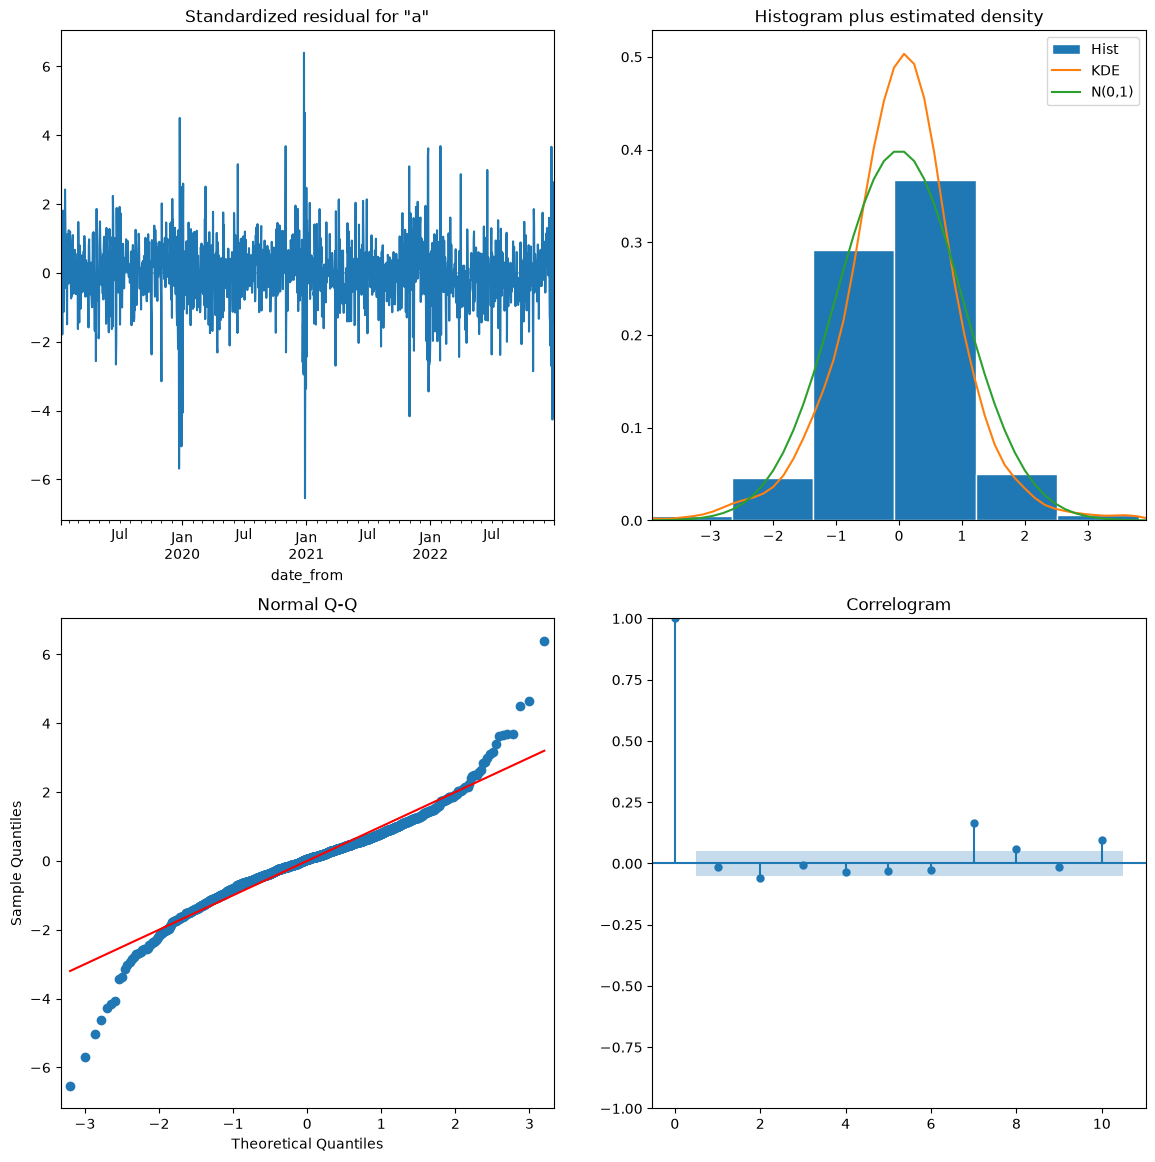

In [30]:
res = m1_results["SARIMAX_1000117"]["res"]
resid = res.resid.iloc[28:]   # skip the first 4 weeks: the filter starts up there (D = 1, s = 7), so their residuals are not real forecast errors

# Diagnostic plots
res.plot_diagnostics(figsize = (14, 14));

**Findings**

The residuals of the fit period (2019 to 2022) of SARIMAX `(1,0,0)(0,1,1,7)` with the baseline X. The model is fitted on the consumption in GWh, which does not change the standardized residuals.

- The standardized residuals are centered at zero and their variance is stable over time. The largest deviations are around the turn of the year (about -5.6 in December 2019 and about +6.3 and -6.2 around January 2021), i.e. in the Christmas and New Year period.
- The distribution has a high peak and heavy tails: most points of the Q-Q plot are on the line, but a few residuals (about -6 and +6 standard deviations) are far away. The **residuals are therefore not normally distributed**. This does not affect the point forecast, but the prediction intervals based on the normal distribution are not reliable.


**2. Stationarity**

In [31]:
test_adf("", resid, 0, print_stationary = True)
test_kpss("", resid, 0, print_stationary = True);

 rejected by ADF      | p-value =   0.0000
 rejected by KPSS     | p-value =   0.0436


**Findings**

ADF rejects a unit root (p < 0.001); KPSS rejects stationarity only marginally (p = 0.044). We treat the residuals as stationary and add no further differencing; the KPSS result likely reflects the remaining autocorrelation at lags 7 and 14 and changes in the residual variance (2020, 2022).

**3. Autocorrelation**

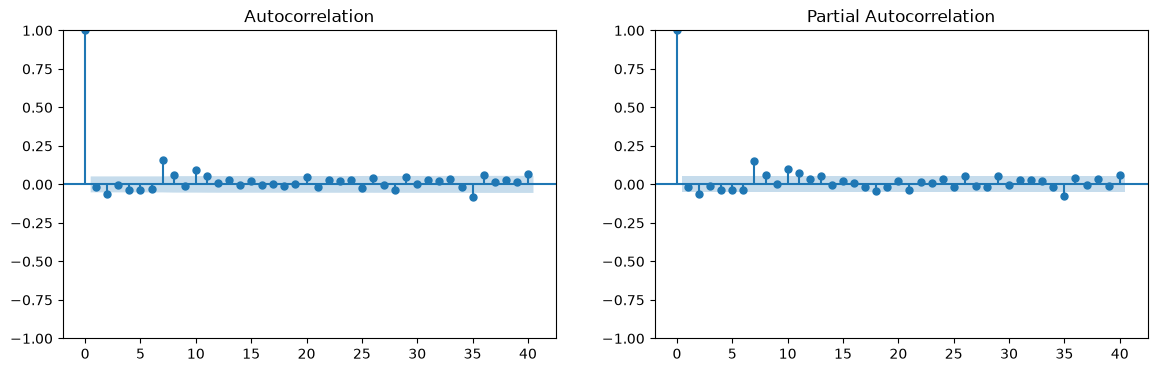

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 4))
plot_acf(resid, lags = 40, ax = ax1);
plot_pacf(resid, lags = 40, ax = ax2);

In [33]:
acorr_ljungbox(resid, lags = [7, 14, 28], model_df = 2)

,lb_stat,lb_pvalue
7,46.051786,8.864273e-09
14,69.641375,3.737895e-10
28,83.562938,5.857048e-08


In [34]:
from statsmodels.tsa.stattools import acf, pacf
lags = [2, 7, 10, 14, 21, 35, 40]
pd.DataFrame({"acf": acf(resid, nlags = 40)[lags], "pacf": pacf(resid, nlags = 40)[lags]}, index = lags).round(3)

,acf,pacf
2,-0.059,-0.060
7,0.157,0.153
10,0.094,0.104
14,-0.001,-0.007
21,-0.019,-0.037
35,-0.082,-0.075
40,0.067,0.061


**Autocorrelation of the residuals**

- The Ljung–Box test rejects "no autocorrelation" at lags 7, 14 and 28 (p < 0.001). With about 1,430 observations the test is very sensitive, so even small autocorrelations are significant: the remaining structure is statistically significant, but small in size (see the ACF).
- Most autocorrelations are inside the 95% confidence band (about ±0.05 for n ≈ 1,430). The only clear one is at the **seasonal lag 7**, where both the ACF and the PACF are positive (0.157 and 0.153). It does not repeat at lags 14 (−0.001) and 21 (−0.019).
- At lags 1 to 6 the autocorrelations are small: lag 2 lies just outside the band (ACF −0.059, PACF −0.060), the other lags are inside it. A single small value does not point to a second AR term.
- There are a few isolated small values (ACF 0.094 at lag 10, −0.082 at lag 35 and 0.067 at lag 40), which we do not model.

A single positive spike at lag 7 in both the ACF and the PACF can be a sign of a seasonal AR term ($P = 1$). The plots give no reason for a second seasonal MA term, since there are no negative values at the seasonal lags.

**Next step**

Compare candidate orders with the same X, by AIC, BIC and the RMSE and MAPE on the validation period: a seasonal AR term ($P = 1$), and $p = 2$ as a check.


### Order selection

The residual diagnostics of the original specification show a small autocorrelation at the seasonal lag 7 (ACF 0.157, PACF 0.153) and a marginal one at lag 2 (−0.06, see above). We therefore compare the following specifications, all with the same X:

| | (p, d, q) | (P, D, Q, s) | Change and reason |
| --- | --- | --- | --- |
| Original | (1, 0, 0) | (0, 1, 1, 7) | initial specification |
| A | (1, 0, 0) | (1, 1, 1, 7) | seasonal AR term, for the spike at lag 7 |
| B | (2, 0, 0) | (0, 1, 1, 7) | second AR term, as a check for lag 2 |
| C | (2, 0, 0) | (1, 1, 1, 7) | both terms |

The specification with the lowest RMSE of the one-day-ahead forecasts (h = 1) on the validation year is chosen. AIC and BIC are reported as well; they are comparable here because all specifications have the same differencing.


In [35]:
candidates = {
    "SARIMAX_1001117": ((1, 0, 0), (1, 1, 1, 7)),
    "SARIMAX_2000117": ((2, 0, 0), (0, 1, 1, 7)),
    "SARIMAX_2001117": ((2, 0, 0), (1, 1, 1, 7)),
}

# start values: the estimates of a converged specification that the candidate contains (new terms at 0)
start_from = {
    "SARIMAX_1001117": "SARIMAX_1000117",       # A contains the original specification
    "SARIMAX_2000117": "SARIMAX_1000117",       # B contains the original specification
    "SARIMAX_2001117": "SARIMAX_1001117",       # C contains A, so A has to be fitted first
}

for name, (order, seasonal_order) in candidates.items():
    m1_results[name] = fit_eval(
        y, X_m1_scaled, order, seasonal_order, VAL_START,
        y_scale = 1000, start_params = m1_results[start_from[name]]["res"].params, name = name,
    )

save_results(m1_results, M1_RESULTS_DIR)
summarize(
    m1_results, ["SARIMAX_1000117", *candidates],
    columns = ("aic", "bic", "rmse", "mape", "first_converged"),
).sort_values("rmse")


[SARIMAX_1001117] refit 1/1 (block from 2023-01-01), 0 left, elapsed 50s, ETA 0s
[SARIMAX_2000117] refit 1/1 (block from 2023-01-01), 0 left, elapsed 2s, ETA 0s
[SARIMAX_2001117] refit 1/1 (block from 2023-01-01), 0 left, elapsed 2s, ETA 0s


,aic,bic,rmse,mape,first_converged
SARIMAX_2001117,13669.064738,13838.091095,24679.939724,1.531681,True
SARIMAX_1001117,13667.187658,13830.931942,24680.375643,1.531844,True
SARIMAX_1000117,13718.100466,13876.562676,25227.820968,1.539813,True
SARIMAX_2000117,13719.787988,13883.532271,25241.036529,1.539844,True


**Findings**

| | Specification | AIC | BIC | RMSE | MAPE |
| --- | --- | ---: | ---: | ---: | ---: |
| C | (2,0,0)(1,1,1,7) | 13,669 | 13,838 | 24,680 | 1.53% |
| A | (1,0,0)(1,1,1,7) | 13,667 | 13,831 | 24,680 | 1.53% |
| Original | (1,0,0)(0,1,1,7) | 13,718 | 13,877 | 25,228 | 1.54% |
| B | (2,0,0)(0,1,1,7) | 13,720 | 13,884 | 25,241 | 1.54% |

Specification C has the lowest RMSE and is chosen. The seasonal AR term is what improves the forecasts: A and C, which have it, reduce the RMSE by about 550 MWh compared with the original specification. The second AR term adds practically nothing: its coefficient in C is close to zero and not significant (0.009, p = 0.62), so C and A are almost the same model (RMSE difference 0.4 MWh).


### Analysis of the residuals: C

Specification C (2, 0, 0) (1, 1, 1, 7) 
------------------------------------------ 
Stationarity Test
 rejected by ADF      | p-value =   0.0000
 rejected by KPSS     | p-value =   0.0164


,lb_stat,lb_pvalue
7,5.758028,0.123995
14,38.057500,0.000037
28,49.751139,0.001523


,abs_resid,resid
date_from,,
2020-12-25,171.429049,171.429049
2020-12-28,155.672077,-155.672077
2019-12-23,150.552106,-150.552106
2020-12-27,123.116652,123.116652
2019-12-25,123.076039,123.076039
2022-12-27,112.966264,-112.966264
2019-12-30,106.250883,-106.250883
2019-12-31,106.032378,-106.032378
2021-11-01,105.908708,-105.908708


,coef,p
ar.L1,0.828,0.000
ar.L2,0.009,0.622
ar.S.L7,0.232,0.000
ma.S.L7,-0.957,0.000


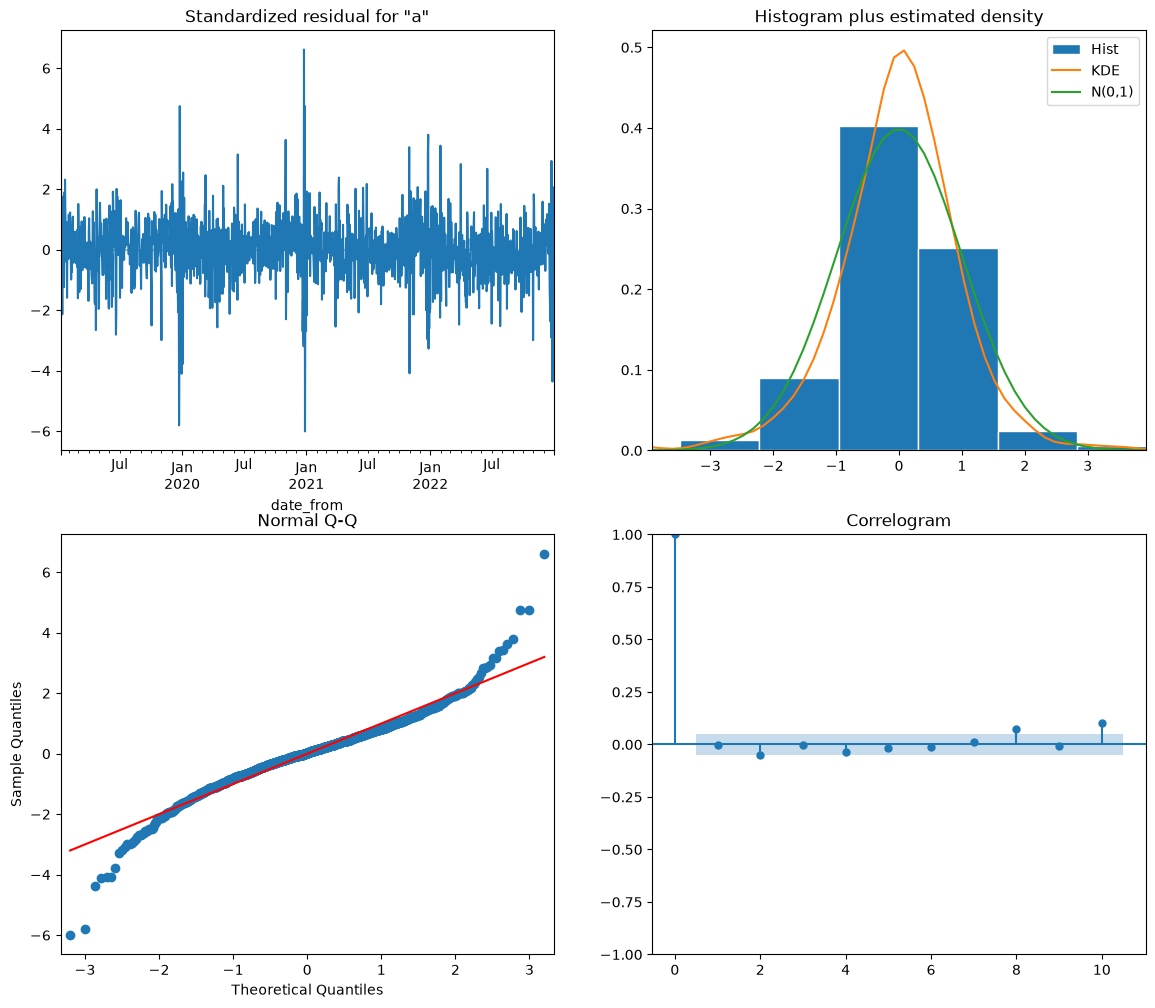

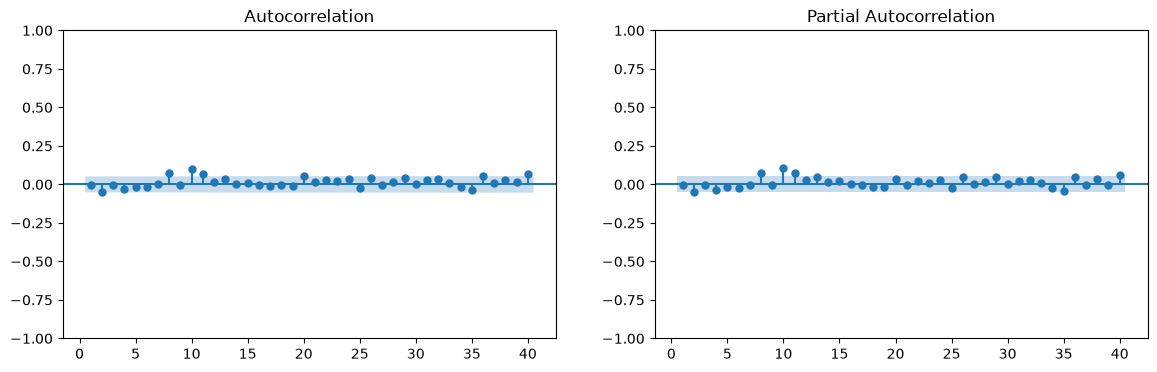

In [36]:
res_c = m1_results["SARIMAX_2001117"]["res"]
resid_c = res_c.resid.iloc[28:]       # skip the first 4 weeks: the filter starts up there (D = 1, s = 7)

# * normality and overview: residuals over time, histogram, Q-Q plot, correlogram
res_c.plot_diagnostics(figsize = (14, 12));

# * stationarity
print("Specification C (2, 0, 0) (1, 1, 1, 7) \n==========================================")
print("------------------------------------------ \nStationarity Test")
test_adf("", resid_c, 0, print_stationary = True)
test_kpss("", resid_c, 0, print_stationary = True)

# * autocorrelation: model_df = number of ARMA parameters of C (ar.L1, ar.L2, ar.S.L7, ma.S.L7)
display(acorr_ljungbox(resid_c, lags = [7, 14, 28], model_df = 4))
fig, (axl, axr) = plt.subplots(1, 2, figsize = (14, 4))
plot_acf(resid_c, lags = 40, zero = False, ax = axl);
plot_pacf(resid_c, lags = 40, zero = False, ax = axr);

# * largest residuals: which days are the outliers
display(resid_c.abs().sort_values(ascending = False).head(15).to_frame("abs_resid").join(resid_c.rename("resid")))

# * ARMA coefficients of C
display(pd.DataFrame({"coef": res_c.params, "p": res_c.pvalues}).filter(regex = r"^(ar|ma)\.", axis = 0).round(3))


**Findings**

- **Autocorrelation.** The Ljung–Box test (model_df = 4) does not reject at lag 7 (p = 0.12): the seasonal AR term removes the spike at the seasonal lag. It still rejects at lags 14 (p < 0.001) and 28 (p = 0.002). The remaining autocorrelations are small and lie at lags 8, 10 and 11 (about +0.07 to +0.10); the other lags are inside the confidence band.
- **Normality.** The residuals are heavy-tailed: the Q-Q plot departs from the line in both tails, and the density is more peaked than the normal. 11 of the 15 largest residuals fall between 23 December and 2 January; three others are on 31 October and 1 November (regional holidays; 31 October 2021 is also the end of daylight saving time). Non-normal residuals do not bias the point forecasts, but prediction intervals based on the normal distribution would be too narrow.
- **Stationarity.** ADF rejects a unit root (p < 0.001). KPSS rejects stationarity at the 5% but not at the 1% level (p = 0.016), most likely because of the clusters of large residuals at the end of each year. Since the seasonal MA coefficient is already close to −1 (−0.957), a further difference is not added; the residuals are treated as stationary.


## Conclusion of Model 1

The chosen specification is **C: SARIMAX (2,0,0)(1,1,1,7)** with the baseline X and month dummies. On the validation year 2023 (h = 1) it reaches an RMSE of 24,680 MWh and a MAPE of 1.53%. This is about half the error of the SARIMA without X (RMSE 49,519) and a third of the seasonal naive forecast (RMSE 81,772). The seasonal AR term removes the autocorrelation at lag 7; the second AR term is close to zero, so C is practically the same model as A.

Limitations:

- **Remaining autocorrelation.** Small autocorrelations are left at lags 8 to 11 (Ljung–Box rejects at lags 14 and 28).
- **Holiday periods.** The largest errors fall in the Christmas–New Year period and on regional holidays, so these days are not fully described by the X. The residuals are heavy-tailed, so normal prediction intervals would be too narrow.
- **Seasonal MA close to −1.** The seasonal MA coefficient is −0.957, so it nearly cancels the seasonal difference. This is the typical sign of over-differencing: if the weekly pattern were exactly the same every week (deterministic seasonality), the seasonal difference would remove it and leave a seasonal MA term of exactly −1. The weekly pattern therefore looks closer to deterministic than to stochastic seasonality. A side effect is a flat likelihood, which makes the optimization slow.

The last point motivates **Model 2**: no differencing, with the weekly pattern described by day-of-week dummies and the yearly pattern by Fourier terms.


# Model 2

## Stationarity of the regression residuals

Model 2 is a **regression with ARMA errors in levels**: neither the consumption nor the X are differenced. Some X are not stationary in levels (see the stationarity tests in Model 1). A regression in levels is only valid if the variables are co-integrated, i.e. if the regression residuals are stationary; otherwise the coefficients are not consistent (Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*, 3rd ed., §10.1). Following §10.2, we therefore first fit the regression without ARMA terms (order (0, 0, 0)) and test its residuals.

The preliminary X contains the day-of-week dummies, the yearly Fourier terms up to K = 10 (the number of Fourier pairs is chosen later, after the ARMA orders), the other baseline X, and a constant. The continuous X are standardized with the fit-period statistics, and the model is fitted on the fit period (2019–2022) only.

The residuals are also the basis for the ARMA orders of Model 2: their ACF and PACF show the autocorrelation that the ARMA errors have to describe.


residuals rejected by ADF      | p-value =   0.0000
residuals stationary (KPSS)    | p-value =   0.0729


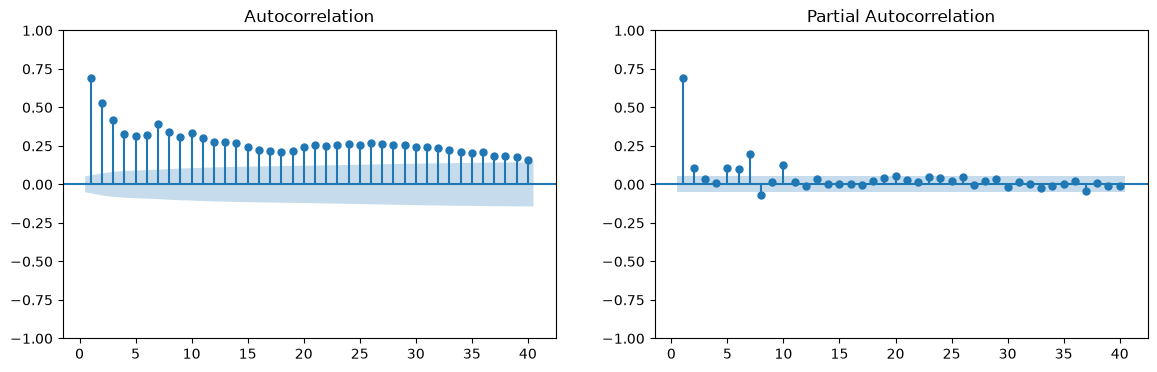

In [37]:
# * standardize with the fit-period statistics, then add the constant (Model 2 has no differencing)
X_prelim_scaled, mu_prelim, sd_prelim = standardize(X_prelim, "2022-12-31")
X_prelim_final = X_prelim_scaled.assign(const = 1.0)

# * naive regression: order (0, 0, 0) = linear regression of y on X (fit period only)
y_fit_prelim = y[:"2022-12-31"].asfreq("D")
X_fit_prelim = X_prelim_final.loc[y_fit_prelim.index].asfreq("D")

res_prelim = SARIMAX(y_fit_prelim / 1000, exog = X_fit_prelim, order = (0, 0, 0)).fit(disp = False, maxiter = 1000)
resid_prelim = res_prelim.resid

# * stationarity of the residuals
test_adf("residuals", resid_prelim, width = 0, print_stationary = True)
test_kpss("residuals", resid_prelim, width = 0, print_stationary = True)

# * ACF / PACF of the residuals: basis for the candidate orders
fig, (axl, axr) = plt.subplots(1, 2, figsize = (14, 4))
plot_acf(resid_prelim, lags = 40, zero = False, ax = axl);
plot_pacf(resid_prelim, lags = 40, zero = False, ax = axr);


#### Findings

**Co-integration**

ADF rejects a unit root (p < 0.001) and KPSS does not reject stationarity (p = 0.073): the residuals of the regression in levels are stationary. The non-stationary X and the consumption are therefore co-integrated, and Model 2 can be estimated in levels without differencing.

**ACF and PACF of the residuals**

- The PACF has one large value at lag 1 (about 0.69) and drops sharply afterwards, which points to an AR(1) term.
- The PACF is positive at the seasonal lag 7 (about 0.20), followed by a small negative value at lag 8, as expected for a multiplicative seasonal AR term ($P = 1$, $s = 7$, no seasonal difference).
- The ACF decays more slowly than an AR(1) with coefficient 0.69 would imply and stays around 0.2 up to lag 40. This suggests a slowly varying component that the X do not capture, which an ARMA(1,1) term with an AR coefficient close to 1 can describe.
- Small values at lags 2, 5, 6 and 10 (about 0.10) are not modelled.

We therefore compare (1,0,0)(1,0,0,7) and (1,0,1)(1,0,0,7).


## Order selection

The ACF and PACF of the regression residuals (see above) give two candidate specifications. Both use the same X as the preliminary regression (day-of-week dummies, yearly Fourier terms up to K = 10, the other baseline X and a constant) and no differencing:

| | (p, d, q) | (P, D, Q, s) | Reason |
| --- | --- | --- | --- |
| A | (1, 0, 0) | (1, 0, 0, 7) | PACF spikes at lag 1 and at the seasonal lag 7 |
| B | (1, 0, 1) | (1, 0, 0, 7) | ACF decays more slowly than an AR(1) implies |

B contains A (with the MA coefficient at 0), so B is fitted with A's estimates as start values. This way the fit of B starts at the likelihood of A and cannot end below it.

The specification with the lowest RMSE of the one-day-ahead forecasts (h = 1) on the validation year is chosen. AIC and BIC are reported as well; they are comparable because both specifications have the same differencing. The number of Fourier pairs K is chosen afterwards, with the chosen orders.


In [38]:
# * results of Model 2: one JSON per experiment
M2_RESULTS_DIR = "results/daily/model2"
m2_results = {}

In [39]:
candidates_m2 = {
    "SARIMAX_1001007": ((1, 0, 0), (1, 0, 0, 7)),       # A
    "SARIMAX_1011007": ((1, 0, 1), (1, 0, 0, 7)),       # B
}

# start values: the estimates of a specification that the candidate contains (new terms at 0)
start_from_m2 = {
    "SARIMAX_1001007": None,                            # A: default start values
    "SARIMAX_1011007": "SARIMAX_1001007",               # B contains A, so A has to be fitted first
}

for name, (order, seasonal_order) in candidates_m2.items():
    start = start_from_m2[name]
    m2_results[name] = fit_eval(
        y, X_prelim_final, order, seasonal_order, VAL_START,
        y_scale = 1000,
        start_params = None if start is None else m2_results[start]["res"].params,
        name = name,
    )

save_results(m2_results, M2_RESULTS_DIR)
summarize(
    m2_results, [*candidates_m2],
    columns = ("aic", "bic", "rmse", "mape", "first_converged"),
).sort_values("rmse")


[SARIMAX_1001007] refit 1/1 (block from 2023-01-01), 0 left, elapsed 27s, ETA 0s
[SARIMAX_1011007] refit 1/1 (block from 2023-01-01), 0 left, elapsed 3s, ETA 0s


,aic,bic,rmse,mape,first_converged
SARIMAX_1001007,13685.540467,13923.449906,24690.01883,1.530583,True
SARIMAX_1011007,13687.343663,13930.539978,24692.743059,1.530453,True


In [40]:
for name in candidates_m2:
    r = m2_results[name]["res"]
    print(name, f"llf = {r.llf:.2f}, iterations = {r.mle_retvals['iterations']}")
    display(pd.DataFrame({"coef": r.params, "p": r.pvalues}).filter(regex = r"^(ar|ma)\.", axis = 0).round(3))


SARIMAX_1001007 llf = -6797.77, iterations = 369


,coef,p
ar.L1,0.729,0.0
ar.S.L7,0.280,0.0


SARIMAX_1011007 llf = -6797.67, iterations = 44


,coef,p
ar.L1,0.721,0.000
ma.L1,0.017,0.562
ar.S.L7,0.280,0.000


**Result**

A has the lowest RMSE (24,690 MWh) and is the simpler specification, so we choose A. The MA term of B does not improve the fit: its coefficient is close to zero and not significant (0.017, p = 0.56), B's log-likelihood is only 0.1 higher than A's (AIC +1.8), and its RMSE is practically the same (24,693 MWh). The slow decay of the ACF is therefore not better described by an ARMA(1,1) term.

Both fits converge. With 45 parameters, the default limit of 15,000 likelihood evaluations of the optimizer was used up before convergence, so the limit was raised to 50,000. This changed A's log-likelihood by only 0.06 and its coefficients not at all, but its RMSE by 46 MWh: differences in RMSE of a few tens of MWh are within the variation of the estimation and should not be read as a difference between specifications.


## Number of Fourier pairs K

With the orders of A, the number of yearly Fourier pairs is varied from K = 1 to 10; all other X stay the same. Each K is fitted with the estimates of K − 1 as start values (K contains K − 1), so its log-likelihood cannot end below that of K − 1.

The K with the lowest RMSE of the one-day-ahead forecasts on the validation year is chosen. AIC and BIC are reported as well.


In [41]:
def fourier_cols(K):
    """ the yearly Fourier columns of the first K pairs """
    return [f"{t}_y{k}" for k in range(1, K + 1) for t in ("sin", "cos")]

ORDER_M2 = ((1, 0, 0), (1, 0, 0, 7))        # specification A

for K in range(1, 11):
    name = f"SARIMAX_1001007_K{K}"
    X_k = X_prelim_final.drop(columns = [c for c in fourier_terms if c not in fourier_cols(K)])
    prev = m2_results.get(f"SARIMAX_1001007_K{K - 1}")       # K contains K - 1: start from its estimates
    m2_results[name] = fit_eval(
        y, X_k, *ORDER_M2, VAL_START,
        y_scale = 1000,
        start_params = None if prev is None else prev["res"].params,
        name = name,
    )

save_results(m2_results, M2_RESULTS_DIR)
summarize(
    m2_results, [f"SARIMAX_1001007_K{K}" for K in range(1, 11)],
    columns = ("aic", "bic", "rmse", "mape", "first_converged"),
)


[SARIMAX_1001007_K1] refit 1/1 (block from 2023-01-01), 0 left, elapsed 18s, ETA 0s
[SARIMAX_1001007_K2] refit 1/1 (block from 2023-01-01), 0 left, elapsed 8s, ETA 0s
[SARIMAX_1001007_K3] refit 1/1 (block from 2023-01-01), 0 left, elapsed 5s, ETA 0s
[SARIMAX_1001007_K4] refit 1/1 (block from 2023-01-01), 0 left, elapsed 5s, ETA 0s
[SARIMAX_1001007_K5] refit 1/1 (block from 2023-01-01), 0 left, elapsed 6s, ETA 0s
[SARIMAX_1001007_K6] refit 1/1 (block from 2023-01-01), 0 left, elapsed 4s, ETA 0s
[SARIMAX_1001007_K7] refit 1/1 (block from 2023-01-01), 0 left, elapsed 8s, ETA 0s
[SARIMAX_1001007_K8] refit 1/1 (block from 2023-01-01), 0 left, elapsed 7s, ETA 0s
[SARIMAX_1001007_K9] refit 1/1 (block from 2023-01-01), 0 left, elapsed 11s, ETA 0s
[SARIMAX_1001007_K10] refit 1/1 (block from 2023-01-01), 0 left, elapsed 7s, ETA 0s


,aic,bic,rmse,mape,first_converged
SARIMAX_1001007_K1,13737.980537,13880.7262,24764.108926,1.526951,True
SARIMAX_1001007_K2,13731.256168,13884.575584,24775.368495,1.519321,True
SARIMAX_1001007_K3,13723.047148,13886.940317,24753.577163,1.517765,True
SARIMAX_1001007_K4,13720.322779,13894.789701,24819.273509,1.52251,True
SARIMAX_1001007_K5,13717.70032,13902.740994,24709.905866,1.515202,True
SARIMAX_1001007_K6,13715.805314,13911.419741,24785.308979,1.52214,True
SARIMAX_1001007_K7,13702.42141,13908.60959,24722.543753,1.519702,True
SARIMAX_1001007_K8,13693.188935,13909.950867,24737.156712,1.532336,True
SARIMAX_1001007_K9,13684.738569,13912.074255,24731.418042,1.528284,True
SARIMAX_1001007_K10,13685.534641,13923.44408,24726.349073,1.531481,True


**Findings**

**K = 5** has the lowest RMSE (24,710 MWh) and also the lowest MAPE (1.515%), so we choose K = 5. AIC would choose K = 9 and BIC K = 1; they are reported for reference only.


## Analysis of Residuals

residuals rejected by ADF      | p-value =   0.0000
residuals rejected by KPSS     | p-value =   0.0100


/var/folders/5g/49r4l15d2n94wslpp3gvq4zc0000gn/T/ipykernel_40692/833649152.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  res = kpss(series, regression = "c", nlags = "auto", result_object = True)


,lb_stat,lb_pvalue
7,2.446195,0.784575
14,31.382970,0.001722
28,43.834253,0.015748


,abs_resid,resid
date_from,,
2020-12-25,153.506984,153.506984
2020-12-28,153.340725,-153.340725
2019-12-23,137.934319,-137.934319
2021-11-01,126.566864,-126.566864
2022-10-31,123.553692,-123.553692
2020-12-27,123.317259,123.317259
2022-12-27,117.807664,-117.807664
2019-12-25,111.530265,111.530265
2019-12-31,103.019020,-103.019020


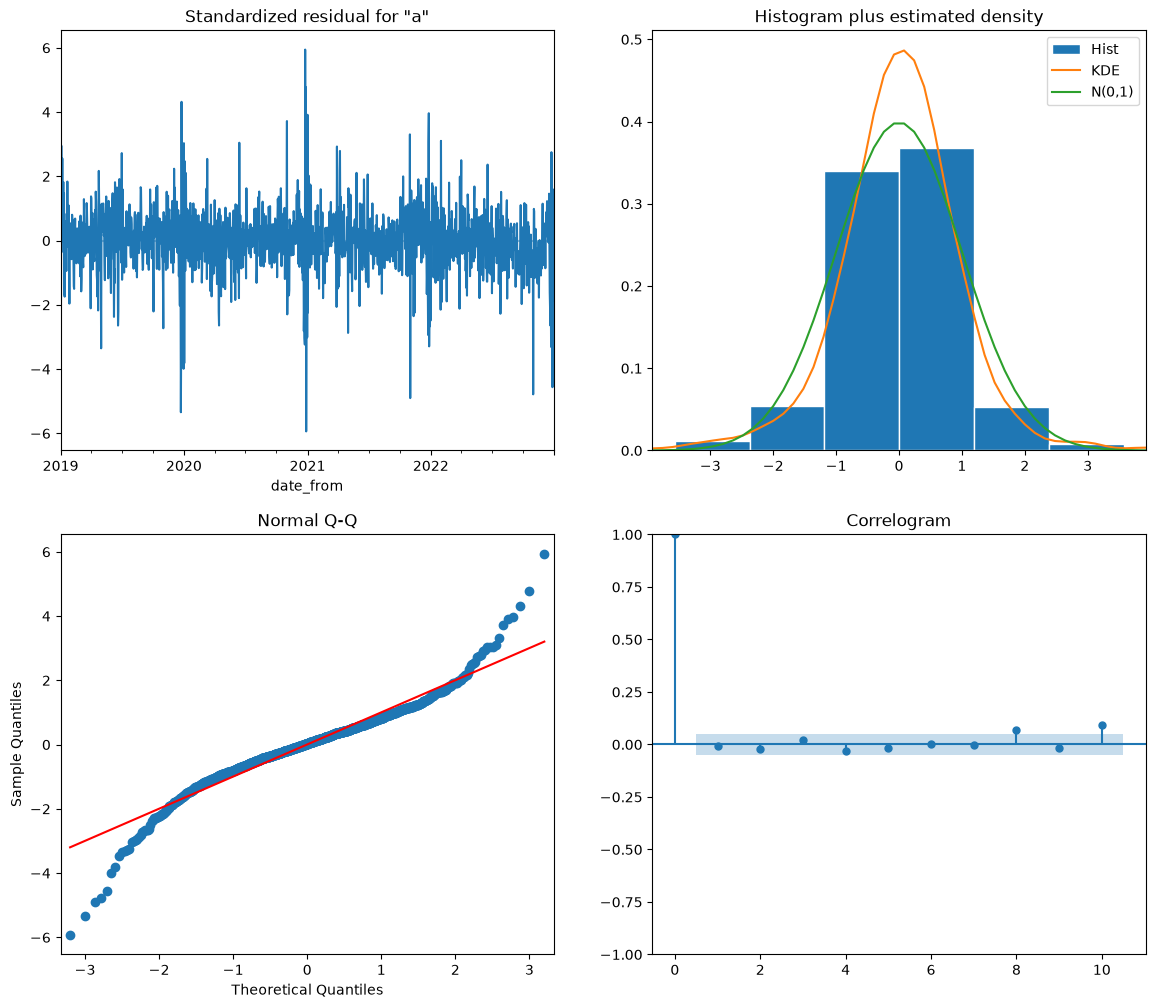

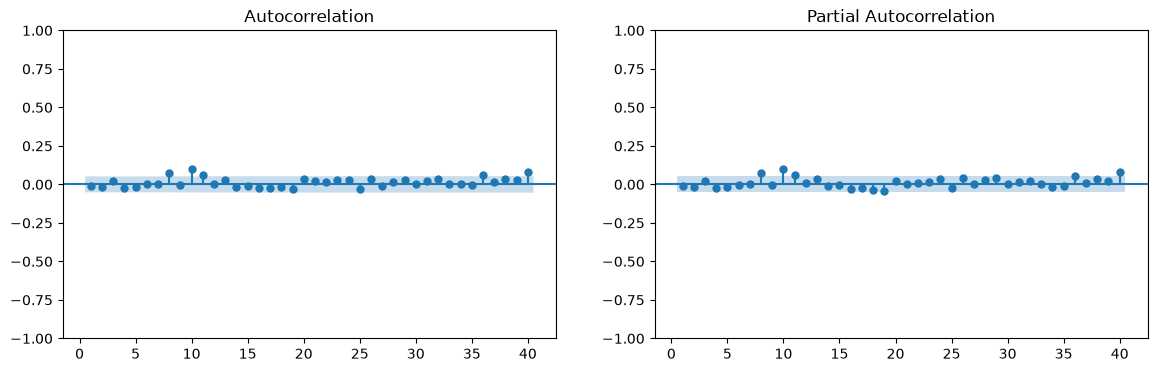

In [42]:
res_m2 = m2_results["SARIMAX_1001007_K5"]["res"]
resid_m2 = res_m2.resid.iloc[28:]      # same start-up window as in Model 1, so the diagnostics are comparable

res_m2.plot_diagnostics(figsize = (14, 12));

test_adf("residuals", resid_m2, width = 0, print_stationary = True)
test_kpss("residuals", resid_m2, width = 0, print_stationary = True)

# model_df = number of ARMA parameters (ar.L1, ar.S.L7)
display(acorr_ljungbox(resid_m2, lags = [7, 14, 28], model_df = 2))
fig, (axl, axr) = plt.subplots(1, 2, figsize = (14, 4))
plot_acf(resid_m2, lags = 40, zero = False, ax = axl);
plot_pacf(resid_m2, lags = 40, zero = False, ax = axr);

resid_m2.abs().sort_values(ascending = False).head(15).to_frame("abs_resid").join(resid_m2.rename("resid"))


naive K=5 rejected by ADF      | p-value =   0.0000
naive K=5 stationary (KPSS)    | p-value =   0.0827


True

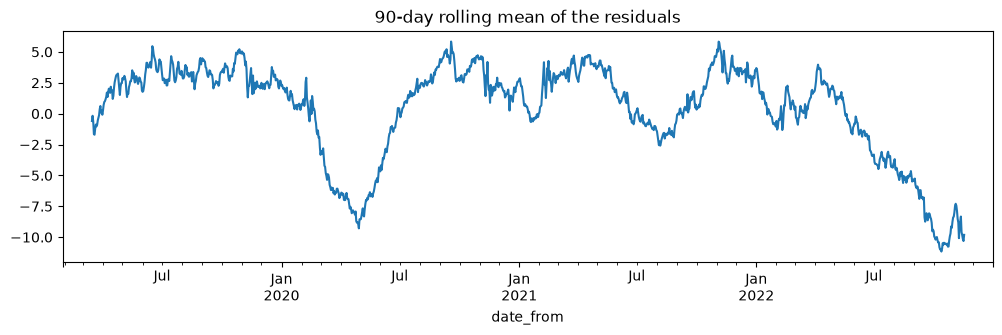

In [43]:
# 1. the residual mean over time: a drift shows up as a slow wave or a level shift
resid_m2.rolling(90, center = True).mean().plot(figsize = (12, 3), title = "90-day rolling mean of the residuals");

# 2. the co-integration check with the final X (K = 5)
X_k5_fit = X_prelim_final.drop(columns = [c for c in fourier_terms if c not in fourier_cols(5)]).loc[y_fit_prelim.index].asfreq("D")
resid_naive_k5 = SARIMAX(y_fit_prelim / 1000, exog = X_k5_fit, order = (0, 0, 0)).fit(disp = False, maxiter = 1000).resid
test_adf("naive K=5", resid_naive_k5, width = 0, print_stationary = True)
test_kpss("naive K=5", resid_naive_k5, width = 0, print_stationary = True)


**Findings**

- **Autocorrelation.** The Ljung–Box test (model_df = 2) does not reject at lag 7 (p = 0.78), but rejects at lags 14 (p = 0.002) and 28 (p = 0.016). The remaining autocorrelations are small and lie at lags 8, 10 and 11, the same lags as in Model 1. Since the two models describe the weekly pattern in different ways (seasonal difference vs. day-of-week dummies), this remaining structure more likely comes from the X they share, e.g. holiday periods, than from the ARMA orders. The ACF and PACF show no new spikes compared with K = 10, so the orders are kept.
- **Normality.** As in Model 1, the residuals are heavy-tailed, with the largest residuals around the turn of the year. Non-normal residuals do not bias the point forecasts, but prediction intervals based on the normal distribution would be too narrow.
- **Stationarity.** ADF rejects a unit root (p < 0.001), but KPSS rejects stationarity (p < 0.01). The 90-day rolling mean of the residuals shows why: it is around +2 to +5 GWh most of the time, but **drops to about −9 GWh in spring 2020 (first COVID lockdown) and to about −10 GWh in autumn 2022 (energy crisis)**. In these periods the model overestimates the consumption; `oxcgrt_stringency` and the day-ahead price do not fully describe the drop in demand. The residuals of the final model are the one-step forecast errors of the regression residuals, so they inherit the same shifts in the mean; since they are nearly white, KPSS detects these shifts more easily than in the strongly autocorrelated regression residuals.

- **Consequence for the forecasts.** At the end of the fit period the residual mean is still around −10 GWh. With h = 1 the AR term corrects most of such a shift, since it uses the actual consumption of the day before. For longer horizons the forecasts return towards the level estimated on 2019–2022, so Model 2 may overestimate the consumption at h = 7, while the seasonal difference of Model 1 adapts to level shifts. 



## Conclusion of Model 2

The chosen specification is **SARIMAX (1,0,0)(1,0,0,7) with K = 5 yearly Fourier pairs**, day-of-week dummies and the baseline X, estimated in levels. On the validation year 2023 (h = 1) it reaches an RMSE of 24,710 MWh and a MAPE of 1.52%. This is about half the error of the SARIMA without X (RMSE 49,519) and a third of the seasonal naive forecast (RMSE 81,772). Unlike Model 1, the fit converges without a flat likelihood, since there is no seasonal MA term close to −1.

Limitations:

- **Remaining autocorrelation.** Small autocorrelations are left at lags 8 to 11 (Ljung–Box rejects at lags 14 and 28), the same lags as in Model 1.
- **Holiday periods.** The largest errors fall around the turn of the year; the residuals are heavy-tailed, so normal prediction intervals would be too narrow.
- **Level shifts.** The model overestimates the consumption during the first COVID lockdown (spring 2020) and the energy crisis (autumn 2022): the X, e.g. `oxcgrt_stringency` and the day-ahead price, do not fully describe these drops in demand. Both models lack this information, but they react differently: Model 1 forecasts from the consumption of the week before, so it adapts to a lasting shift within about a week, while Model 2 forecasts from the level estimated on 2019–2022 and carries a shift only through its AR terms, whose effect fades with the horizon. This may bias Model 2's forecasts at longer horizons.



# Model 1 vs. Model 2

In [44]:
comparison = pd.DataFrame({
    "Model 1: (2,0,0)(1,1,1,7), month dummies": m1_results["SARIMAX_2001117"],
    "Model 2: (1,0,0)(1,0,0,7), K = 5": m2_results["SARIMAX_1001007_K5"],
}).T[["rmse", "mape"]]
comparison

,rmse,mape
"Model 1: (2,0,0)(1,1,1,7), month dummies",24679.939724,1.531681
"Model 2: (1,0,0)(1,0,0,7), K = 5",24709.905866,1.515202



| Model | Specification | RMSE | MAPE |
| --- | --- | ---: | ---: |
| Model 1 | (2,0,0)(1,1,1,7), seasonal difference, month dummies | 24,680 | 1.53% |
| Model 2 | (1,0,0)(1,0,0,7), levels, day-of-week dummies, K = 5 | 24,710 | 1.52% |

**Model 1 has the lower RMSE** of the one-day-ahead forecasts on the validation year, so **it is chosen as the final SARIMAX model**. Model 2 has a slightly lower MAPE; the two models are very close at h = 1. AIC and BIC are not compared, since the models have different differencing. 

# Final Model Evaluation

## Validation: Forecast horizons h = 1 to 7 (Model 1)


In [45]:
m1_results["SARIMAX_2001117"] = fit_eval(
    y, X_m1_scaled, (2, 0, 0), (1, 1, 1, 7), VAL_START,
    y_scale = 1000,
    start_params = m1_results["SARIMAX_1001117"]["res"].params,
    horizon = 7,
    name = "SARIMAX_2001117",
)
save_results(m1_results, M1_RESULTS_DIR)

# one row per horizon
pd.DataFrame({
    h: {m: m1_results["SARIMAX_2001117"][f"{m}_h{h}"] for m in ("rmse", "mape", "bias")}
    for h in range(1, 8)
}).T.rename_axis("h")


[SARIMAX_2001117] refit 1/1 (block from 2023-01-01), 0 left, elapsed 2s, ETA 0s
[SARIMAX_2001117] forecasts for h = 1..7: 0s


,rmse,mape,bias
h,,,
1,24679.939724,1.531681,-693.074516
2,32742.123090,2.053280,-1116.808107
3,35670.625494,2.260624,-1382.782870
4,36550.555611,2.319018,-1659.362261
5,37354.355664,2.384951,-1983.425322
6,38302.386484,2.429756,-2027.298681
7,39910.030994,2.523273,-2166.898845


**Findings**

- **The error grows with the horizon**, from an RMSE of 24,680 MWh at h = 1 to 39,910 MWh at h = 7. The largest step is from h = 1 to h = 2 (+33%): at h = 1 the model uses the actual consumption of the day before, from h = 2 on it uses its own forecast instead. After that the RMSE grows by only 2–4% per day.
- **Bias.** The bias is negative at all horizons, so the model slightly overestimates the consumption of 2023, and more so at longer horizons. It is small compared with the RMSE (about 5% of it at h = 7, about 0.2% of the daily consumption), so the error comes mainly from day-to-day variation, not from a systematic offset.
- **Comparison with the seasonal naive forecast.** The seasonal naive forecast uses the consumption one week earlier, so it is a forecast from an origin 7 days before. At h = 7 Model 1 has less than half its error (39,910 vs. 81,772 MWh).


## Test: Forecasts on 2024 (Model 1)

In [48]:
TEST_START = "2024-01-01"
TEST_RESULTS_DIR = "results/daily/test"

# * X for 2019-2024: the same columns as X_m1; the month dummies are made again from the full data
X_m1_all = pd.concat([
    data_daily[[c for c in X_m1.columns if not c.startswith("month_")]],
    pd.get_dummies(data_daily["month"], prefix = "month", drop_first = True),
], axis = 1).astype(float)[list(X_m1.columns)]
assert list(X_m1_all.columns) == list(X_m1.columns)

# * standardize with the statistics of the new fit period 2019-2023
X_m1_all_scaled, mu_test, sd_test = standardize(X_m1_all, "2023-12-31")
y_all = data_daily.set_index("date_from")["actual_consumption"]

# * check before the single test run: the data end on 2024-12-31 and the X have no missing values in 2024
print(y_all.index.min().date(), y_all.index.max().date(), "| missing X in 2024:", int(X_m1_all_scaled.loc[TEST_START:].isna().sum().sum()))


# * fit once on 2019-2023, forecast 2024 for h = 1..7
test_result = fit_eval(
    y_all, X_m1_all_scaled, (2, 0, 0), (1, 1, 1, 7), TEST_START,
    y_scale = 1000,
    start_params = m1_results["SARIMAX_2001117"]["res"].params,   # start values only: the parameters are re-estimated on 2019-2023
    horizon = 7,
    name = "test_SARIMAX_2001117",
)
save_result("SARIMAX_2001117", test_result, TEST_RESULTS_DIR)

pd.DataFrame({
    h: {m: test_result[f"{m}_h{h}"] for m in ("rmse", "mape", "bias")}
    for h in range(1, 8)
}).T.rename_axis("h")



2019-01-01 2024-12-31 | missing X in 2024: 0
[test_SARIMAX_2001117] refit 1/1 (block from 2024-01-01), 0 left, elapsed 32s, ETA 0s
[test_SARIMAX_2001117] forecasts for h = 1..7: 0s


,rmse,mape,bias
h,,,
1,29859.540183,1.743164,1148.865387
2,37922.796248,2.166620,2599.325324
3,38734.232067,2.331079,4321.596398
4,40387.391987,2.415760,5430.179095
5,42518.363737,2.552261,6253.403587
6,43500.660263,2.639956,6910.129986
7,44482.016901,2.728733,7303.876545


In [49]:
# Seasonal Naive
evaluate(y_all[TEST_START:], y_all.shift(7)[TEST_START:]);

🔹 rmse = 89643.63
🔹 mape = 4.67%


**Findings**

The model is fitted once on 2019–2023 and forecasts every day of 2024 at the horizons h = 1 to 7. This is the only run on the test year.
    
- **Error level.** The errors are higher than on the validation year (RMSE at h = 1: 29,860 vs. 24,680 MWh; at h = 7: 44,482 vs. 39,910 MWh). The validation results were used to choose the model and are therefore somewhat optimistic. The MAPE stays below 2% at h = 1 and below 3% at h = 7.
- **Horizon.** As on the validation year, the largest step is from h = 1 to h = 2, when the model has to use its own forecast instead of the actual consumption of the day before.
- **Bias.** Unlike on the validation year, the **bias is positive** and grows with the horizon: the model underestimates the consumption of 2024, at h = 7 by about 7,300 MWh on average (about 16% of the RMSE).


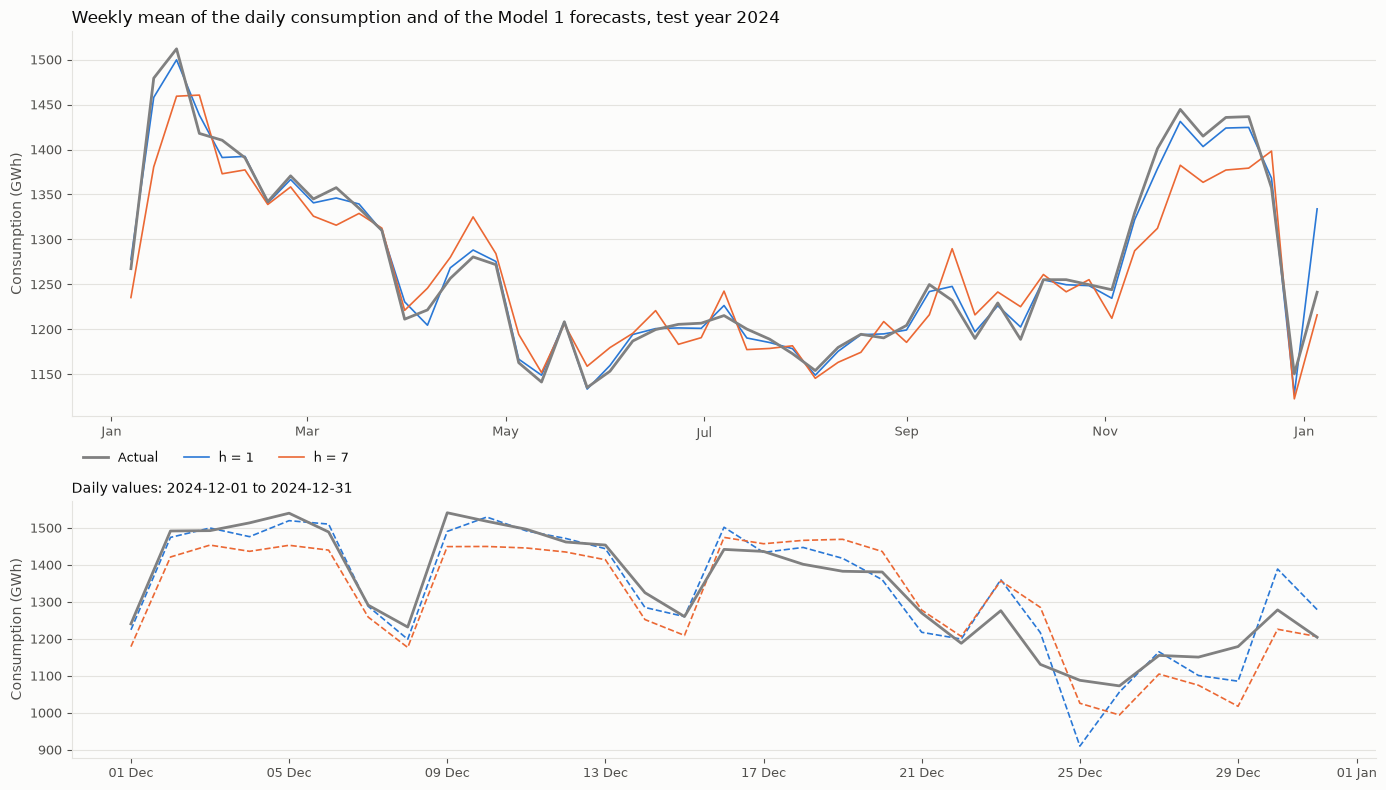

In [56]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# * colors: actual in neutral ink, the shortest and the longest horizon in two contrasting hues
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SHOWN = {"h1": ("#2a78d6", "h = 1"), "h7": ("#eb6834", "h = 7")}
ZOOM = ("2024-12-01", "2024-12-31")          # a month with daily values (Christmas)

y_hat_h = test_result["y_hat_h"] / 1000      # GWh
actual = y_all[TEST_START:] / 1000


def style(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(axis = "y", color = GRID, linewidth = 0.8)
    ax.tick_params(colors = MUTED, labelsize = 9)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)


# * Figure 1: weekly means of 2024 (the weekly cycle averaged out), daily values in the zoom
weekly_actual = actual.resample("W").mean()
weekly_hat = y_hat_h.resample("W").mean()

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize = (14, 8), height_ratios = [3, 2], facecolor = SURFACE)

# top: weekly means
ax_full.plot(weekly_actual, color = "grey", linewidth = 2, label = "Actual", zorder = 3)
for col, (color, label) in SHOWN.items():
    ax_full.plot(weekly_hat[col], color = color, linewidth = 1.2, label = label, zorder = 2)
ax_full.set_title("Weekly mean of the daily consumption and of the Model 1 forecasts, test year 2024", loc = "left", color = INK)
ax_full.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

# bottom: daily values of one month
ax_zoom.plot(actual[ZOOM[0]:ZOOM[1]], color = "grey", linewidth = 2, label = "Actual", zorder = 3)
for col, (color, label) in SHOWN.items():
    ax_zoom.plot(y_hat_h[col][ZOOM[0]:ZOOM[1]], color = color, linewidth = 1.2, linestyle = "--", label = label, zorder = 2)
ax_zoom.set_title(f"Daily values: {ZOOM[0]} to {ZOOM[1]}", loc = "left", color = INK, fontsize = 10)
ax_zoom.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

for ax in (ax_full, ax_zoom):
    style(ax)
    ax.set_ylabel("Consumption (GWh)", color = MUTED)
ax_full.legend(ncol = 3, frameon = False, loc = "upper left", bbox_to_anchor = (0, -0.06), fontsize = 9, labelcolor = INK)
plt.tight_layout()
plt.show()


# Conclusion

- **Final model.** SARIMAX (2,0,0)(1,1,1,7) with the baseline X and month dummies (Model 1). It was chosen over Model 2 (no differencing, day-of-week dummies, K = 5 Fourier pairs) by the RMSE of the one-day-ahead forecasts on the validation year 2023 (24,680 vs. 24,710 MWh); the two models are very close.
- **Test year 2024.** Fitted once on 2019–2023, the model reaches an RMSE of 29,860 MWh (MAPE 1.74%) at h = 1 and 44,482 MWh (MAPE 2.73%) at h = 7. The error is higher than on the validation year, and the model underestimates the consumption of 2024, increasingly with the horizon.
- **Limitations.** The largest errors fall in the Christmas–New Year period and on regional holidays; small autocorrelations remain at lags 8 to 11; the residuals are heavy-tailed, so normal prediction intervals would be too narrow. The X are the actual values of the forecast days (ex-post), which is optimistic compared with a deployment that would use weather forecasts, more so at longer horizons.


In [62]:
# * export the test forecasts for the dashboard: index date_from, one column per horizon (forecast, MWh)
EXPORT_PATH = Path(TEST_RESULTS_DIR) / "sarimax_daily_test_predictions.csv"

out = test_result["y_hat_h"].rename(columns = lambda c: f"y_{c}").rename_axis("date_from")
out.to_csv(EXPORT_PATH)
out.head(8)

,y_h1,y_h2,y_h3,y_h4,y_h5,y_h6,y_h7
date_from,,,,,,,
2024-01-01,1.133428e+06,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-02,1.368561e+06,1.462892e+06,NaN,NaN,NaN,NaN,NaN
2024-01-03,1.279279e+06,1.361087e+06,1.441292e+06,NaN,NaN,NaN,NaN
2024-01-04,1.360961e+06,1.298181e+06,1.367737e+06,1.435920e+06,NaN,NaN,NaN
2024-01-05,1.344348e+06,1.326764e+06,1.273386e+06,1.332517e+06,1.390480e+06,NaN,NaN
2024-01-06,1.192855e+06,1.174039e+06,1.159088e+06,1.113711e+06,1.163979e+06,1.213254e+06,NaN
2024-01-07,1.264534e+06,1.218004e+06,1.202006e+06,1.189296e+06,1.150719e+06,1.193453e+06,1.235343e+06
2024-01-08,1.458024e+06,1.487718e+06,1.448157e+06,1.434557e+06,1.423752e+06,1.390957e+06,1.427286e+06
